# Is a Predictable Process Always a Capable Process?

In [1]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

import matplotlib.patheffects as pe

%matplotlib inline

# Helper function

In [3]:
# xmr process statistics calculations
def xmr_process_stats(data):
    
    # Calculate mean
    mean = data.mean()
    
    # Calculate the moving range
    mRs = data.diff().abs()
    ave_mR = mRs.mean()

    # Calculate process limits
    UPL = mean + (2.660 * ave_mR)
    LPL = mean - (2.660 * ave_mR)
    URL = 3.268 * ave_mR
    
    return {
        'Mean': mean,
        'Ave. mR': ave_mR,
        'UPL': UPL,
        'LPL': LPL,
        'URL': URL
    }

In [7]:
def combo_chart(data, labels, USL, LSL, Target, outside_spec=True, round_value=2):
    
    # Calculate moving range
    mRs = round(data.diff().abs(), round_value)
    
    # Calculate process stats
    stats = xmr_process_stats(data)
    
    # Get process stats
    mean = stats['Mean']
    ave_mR = stats['Ave. mR']
    
    # Process limits
    UPL = stats['UPL']
    LPL = stats['LPL']
    URL = stats['URL']
    
    # Specify x chart line parameters
    xchart_lines = [
        (mean, "-", "black"),
        (UPL, "--", "#d72323"),
        (LPL, "--", "#d72323")
    ]

    # Specify mR chart parameters
    hist_lines = [
        (USL, "-", "grey"),
        (LSL, "-", "grey"),
        (Target, "-", "#014421")
    ]
    
    # Create matplotlib figure
    fig, axs = plt.subplots(nrows=1, 
                           ncols=2, 
                           figsize=(12,6),
                           dpi=300,
                           gridspec_kw={'width_ratios': [2,1]},
                           sharey=True)
    
    # Specify assignable cause condition
    above_fill_UPL = data > UPL
    below_fill_LPL = data < LPL

    plt.subplots_adjust(wspace=0)

    # X chart
    axs[0].plot(labels, 
                data, 
                marker='o', 
                markersize=12,
                markeredgecolor="black",
                linewidth=3,
                zorder=4)
    
    # Highlight observations above UPL
    axs[0].plot(
        labels[above_fill_UPL],
        data[above_fill_UPL],
        marker='o',
        markersize=12,
        markeredgecolor='black',
        markerfacecolor='#d72323',
        linestyle='none',
        zorder=5
    )

    # Highlight observations below LPL
    axs[0].plot(
        labels[below_fill_LPL],
        data[below_fill_LPL],
        marker='o',
        markersize=12,
        markeredgecolor='black',
        markerfacecolor='#d72323',
        linestyle='none',
        zorder=5
    )  

    # Specify xticks for x chart
    tick_positions = np.arange(1, len(labels)+1, 1)
    axs[0].set_xticks(tick_positions)
    axs[0].set_xticklabels(labels, 
                        ha='center', 
                        fontsize=12)

    for value, line_type, color in xchart_lines:
        axs[0].axhline(value, 
                       ls=line_type,
                       linewidth=3,
                       c=color)

    # Process Histogram
    bin_edges = np.histogram_bin_edges(data, bins='auto')

    # Add specification limits while preserving the original bin widths
    bin_width = np.diff(bin_edges).mean()

    if bin_edges[0] < LSL < bin_edges[-1]:
        bin_edges = np.sort(np.r_[bin_edges, LSL])

    if bin_edges[0] < USL < bin_edges[-1]:
        bin_edges = np.sort(np.r_[bin_edges, USL])

    counts, edges = np.histogram(data, bins=bin_edges)

    for count, lower, upper in zip(counts, edges[:-1], edges[1:]):
        color = '#d72323' if upper <= LSL or lower >= USL else '#3A87C8'

        axs[1].barh(
            lower,
            count,
            height=upper - lower,
            align='edge',
            color=color,
            edgecolor='white'
        )

    # Add specification and target lines
    for value, line_type, color in hist_lines:
        axs[1].axhline(
            value,
            ls=line_type,
            linewidth=3,
            c=color
        )

    # Get x limit of subplots
    xchart_lim = axs[0].get_xlim()[0]
    hist_xlim = axs[1].get_xlim()[1]

    # Define annotation values
    annotations = [
        ("UPL", xchart_lim, UPL, axs[0]),
        ("LPL", xchart_lim, LPL, axs[0]),
        ("$\overline{{X}}$", xchart_lim, mean, axs[0]),
        ("USL", hist_xlim, USL, axs[1]),
        ("LSL", hist_xlim, LSL, axs[1]),
        ("Target", hist_xlim, Target, axs[1]),
    ]

    # Define colors for each annotation
    colors = {
        'Target': '#014421',
        'USL': '#808080',
        'LSL': '#808080'
    }

    # Add central line and process limit annotations
    for label, x_pos, y_pos, axis in annotations:
        color = colors.get(label, '#000000')

        axis.annotate(
            label,
            xy=(axis.get_xlim()[0], y_pos),
            xytext=(x_pos, y_pos),
            ha="center",
            va="center",
            fontsize=14,
            bbox=dict(
                facecolor='white',
                edgecolor='black',
                boxstyle='round'
            ),
            arrowprops=dict(
                color=color,
                lw=1,
                path_effects=[
                    pe.Stroke(linewidth=2, foreground='black'),
                    pe.Normal()
                ]
            )
        )


    axs[0].set_title('X Chart', fontsize=16)
    axs[1].set_title('Process Histogram', fontsize=16)

    # Remove x and y ticks
    for ax in axs:
        ax.set_yticks([])

    axs[0].locator_params(axis="x", nbins=15)

    axs[1].set_axisbelow(False)
    axs[1].grid(
        True,
        axis='x',
        color='white',
        linewidth=1,
        zorder=10
    )

    # Despine
    sns.despine(ax=axs[0], left=True)
    # sns.despine(ax=axs[1])

    sns.despine(ax=axs[0], left=True, bottom=True)
    sns.despine(ax=axs[1], bottom=True)

    axs[1].spines['left'].set_color('black')
    axs[1].spines['left'].set_linewidth(1.2)
    axs[1].spines['left'].set_visible(True)

    axs[0].set_xticks([])
    axs[1].set_xlabel('')

    # Remove xticks from histogram
    axs[1].tick_params(axis='x', 
                       which='both', 
                       bottom=False, 
                       labelbottom=False)

    return fig, axs

# Import data

In [20]:
base_url = 'https://raw.githubusercontent.com/jimlehner/The-Math-Matters/main/is-predictable-always-capable/data/'

files = [
    'electrical_resistance_measurements.csv',
    'machine_screw_machine_1.csv',
    'machine_screw_machine_2.csv',
    'machine_screw_machine_3.csv',
    'magnetic_reciever_depth_of_cut.csv'
]

for file in files:
    url = base_url + file

    try:
        df = pd.read_csv(url)
        print(f'{file}: Loaded successfully')
    except Exception as e:
        print(f'{file}: FAILED - {e}')

electrical_resistance_measurements.csv: Loaded successfully
machine_screw_machine_1.csv: Loaded successfully
machine_screw_machine_2.csv: Loaded successfully
machine_screw_machine_3.csv: Loaded successfully
magnetic_reciever_depth_of_cut.csv: Loaded successfully


In [73]:
base_url = 'https://raw.githubusercontent.com/jimlehner/The-Math-Matters/main/is-predictable-always-capable/data/'

resistance_df = pd.read_csv(base_url + 'electrical_resistance_measurements.csv')
machine_screw_1_df = pd.read_csv(base_url + 'machine_screw_machine_1.csv')
machine_screw_2_df = pd.read_csv(base_url + 'machine_screw_machine_2.csv')
machine_screw_3_df = pd.read_csv(base_url + 'machine_screw_machine_3.csv')
fill_weights_df = pd.read_csv(base_url + 'fill_weights.csv')
mag_reciever_df = pd.read_csv(base_url + 'magnetic_reciever_depth_of_cut.csv')

# Figure 2. Resistance combo chart

In [47]:
# Calculate process stats
resistance_stats = xmr_process_stats(resistance_df['Resistance'])
resistance_stats

{'Mean': 4498.176470588235,
 'Ave. mR': 318.8128078817734,
 'UPL': 5346.218539553753,
 'LPL': 3650.1344016227176,
 'URL': 1041.8802561576354}

In [48]:
USL = 5295
LSL = 3395
Target = 4345

data = resistance_df['Resistance']
labels = resistance_df['Value']

(<Figure size 3600x1800 with 2 Axes>,
 array([<Axes: title={'center': 'X Chart'}>,
        <Axes: title={'center': 'Process Histogram'}>], dtype=object))

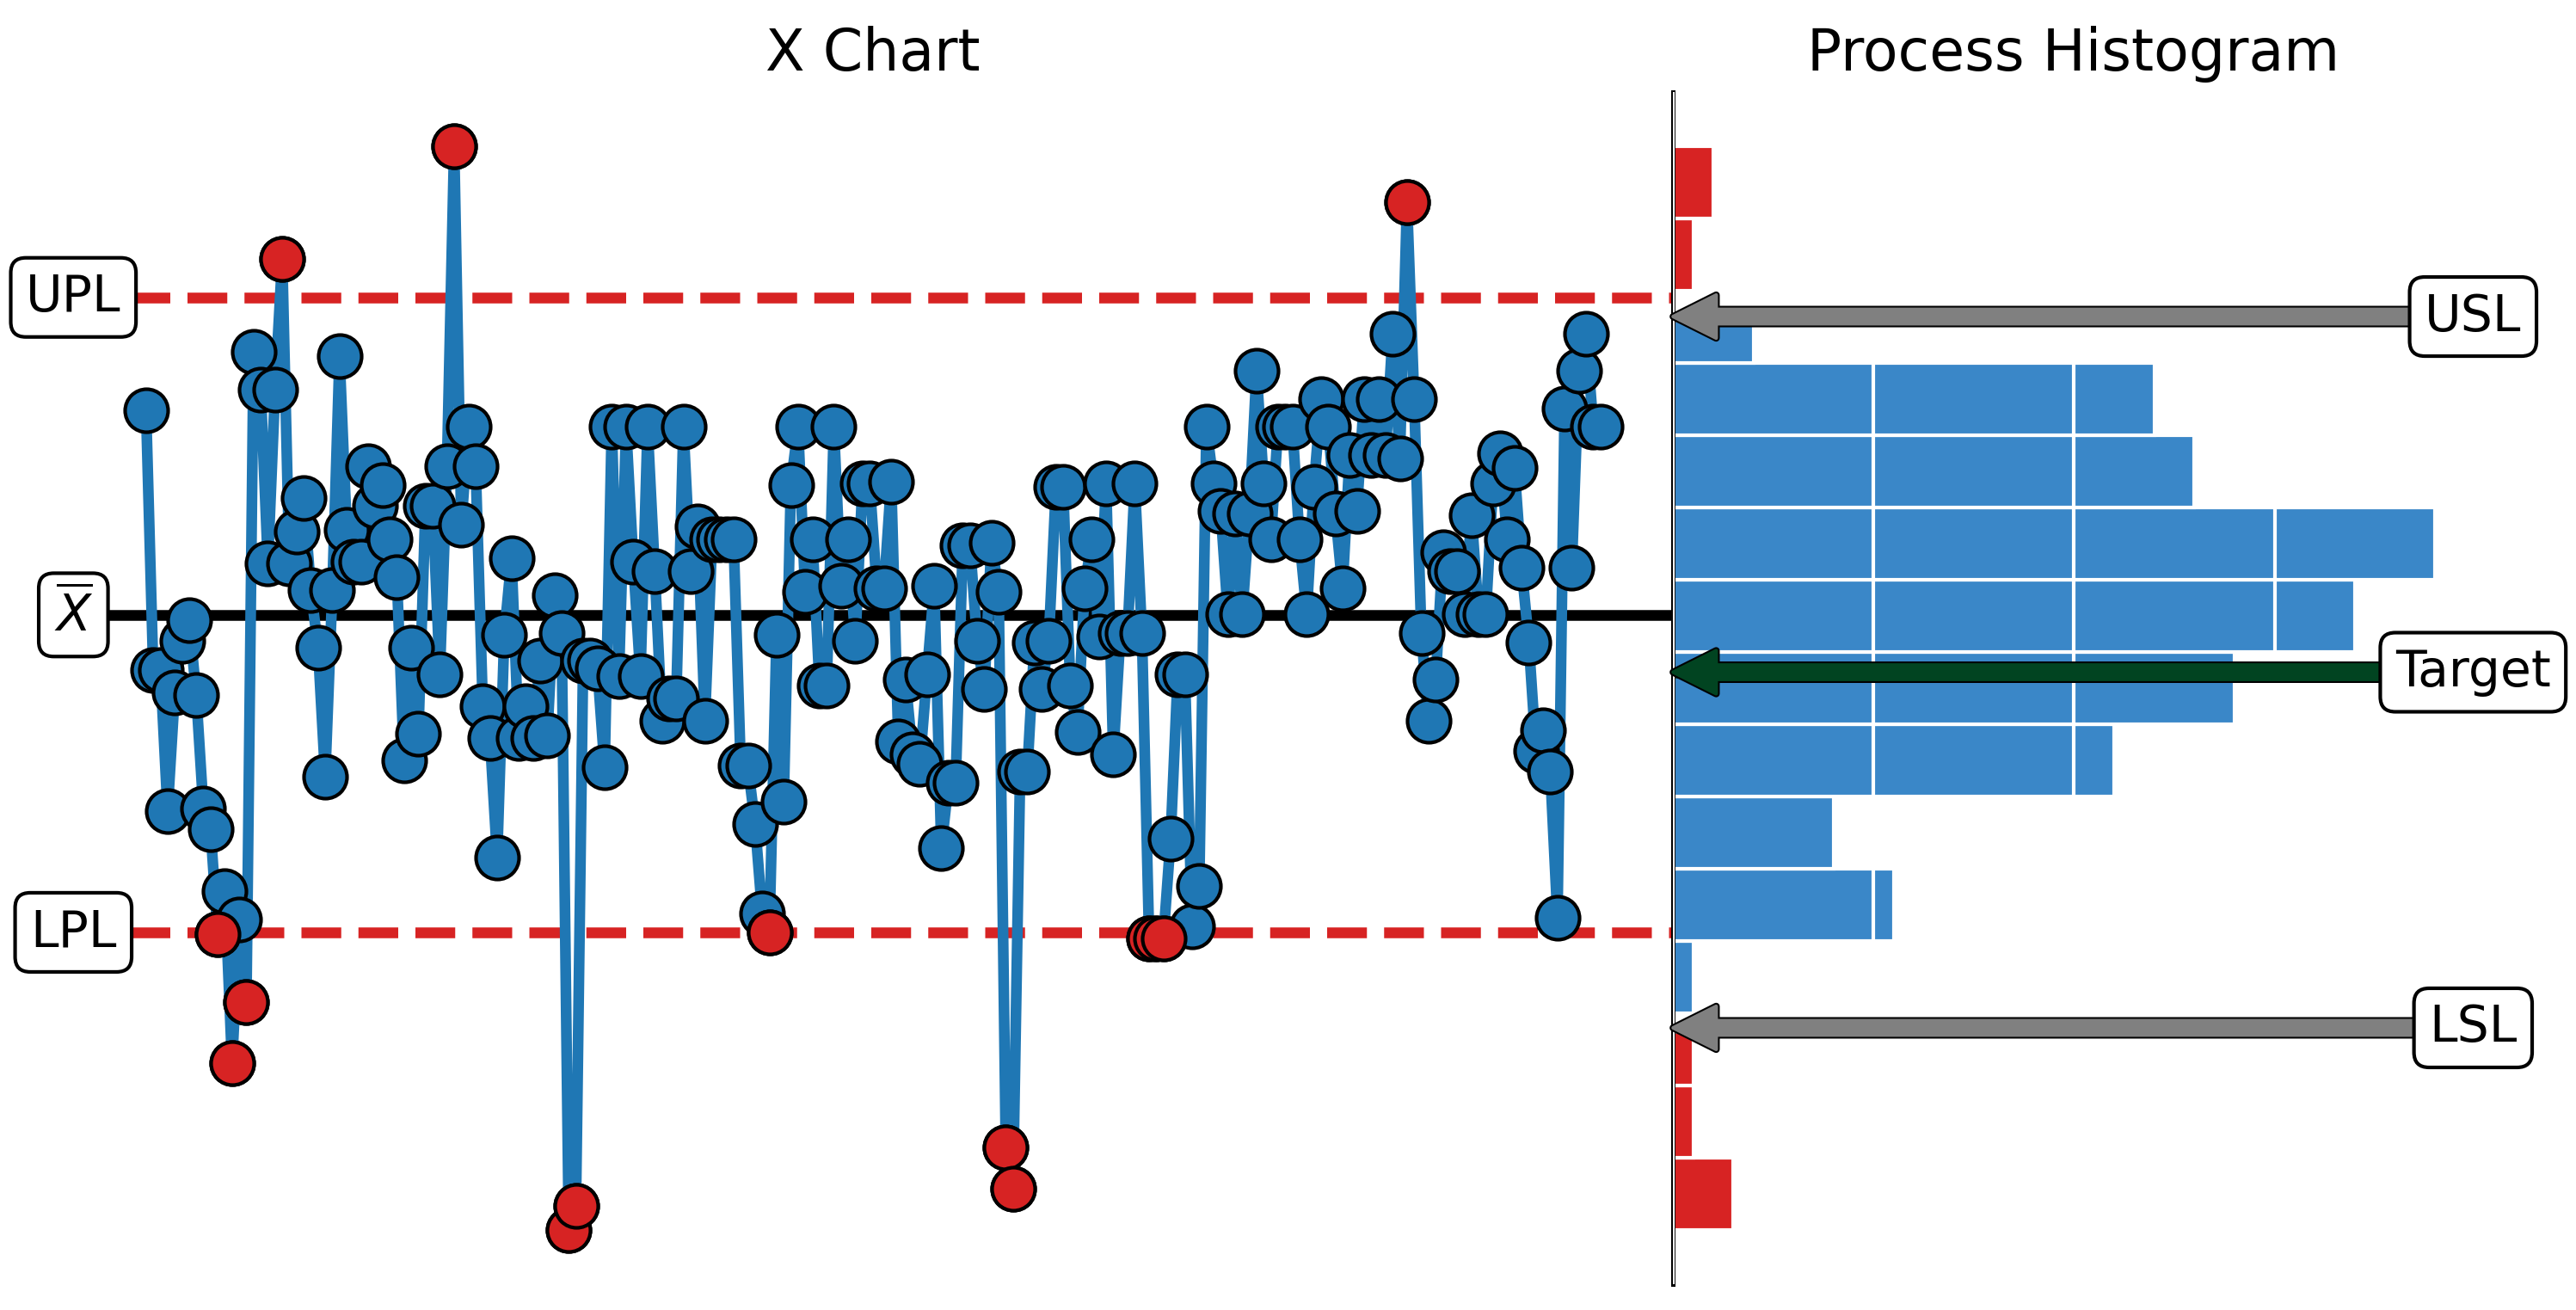

In [49]:
combo_chart(data, labels, USL, LSL, Target)

# Figure 3. Operational Definition 

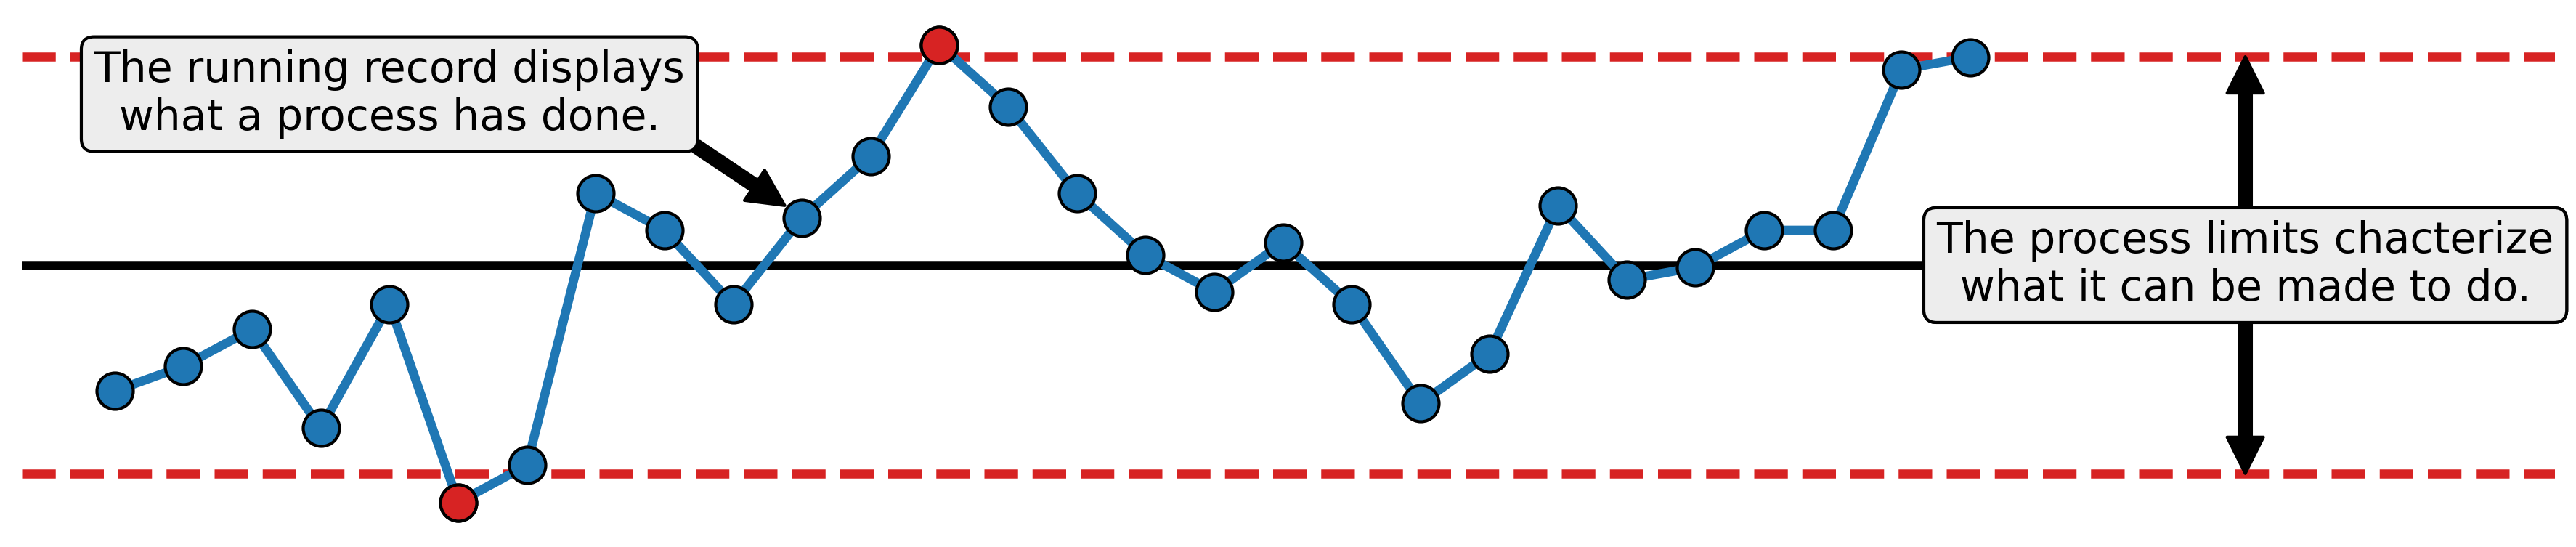

In [141]:
data = fill_weights_df['Fill Weight (g)']
labels = fill_weights_df['Sample']

depth_of_cut_stats = xmr_process_stats(data)
mean = depth_of_cut_stats['Mean']
UPL = depth_of_cut_stats['UPL']
LPL = depth_of_cut_stats['LPL']

lines = [
    (mean, "-", "black"),
    (UPL, "--", "#d72323"),
    (LPL, "--", "#d72323")
]

fig, ax = plt.subplots(
    figsize=(15, 3), 
    dpi=300, 
)

ax.plot(
    data, 
    marker='o', 
    markersize=12,
    markeredgecolor="black",
    linewidth=3,
    zorder=4
       )

# Specify assignable cause condition
above_fill_UPL = data > UPL
below_fill_LPL = data < LPL

# Highlight observations above UPL
ax.plot(
    data[above_fill_UPL],
    marker='o',
    markersize=12,
    markeredgecolor='black',
    markerfacecolor='#d72323',
    linestyle='none',
    zorder=5
)

ax.plot(
    data[below_fill_LPL],
    marker='o',
    markersize=12,
    markeredgecolor='black',
    markerfacecolor='#d72323',
    linestyle='none',
    zorder=5
)

# Plot X chart limits and center line
for value, line_type, color in lines:
    ax.axhline(
        value,
        ls=line_type,
        linewidth=3,
        c=color
    )
    
# Extend the x-axis to create room to the right of the data
x_start = ax.get_xlim()[0]
x_end = len(labels) + 7.5

ax.set_xlim(x_start, x_end)    

# Annotations
ax.annotate(
    r"The running record displays" "\n" 
    r"what a process has done.",
    xy=(9.75, 980),
    xytext=(4, 1025),
    ha='center',
    va='center',
    fontsize=14,
    bbox=dict(facecolor='#EDEDED', boxstyle='round'),
    arrowprops=dict(
        color='black',
        linewidth=1
    )
)

# Add annotations pointing to both process limits
ax.annotate(
    r"The process limits chacterize" "\n"
    "what it can be made to do.",
    xy=(31, LPL),
    xytext=(31, mean),
    ha='center',
    va='center',
    fontsize=14,
    bbox=dict(facecolor='#EDEDED', boxstyle='round'),
    arrowprops=dict(
        color='black',
        linewidth=1
    )
)

ax.annotate(
    r"The process limits chacterize" "\n"
    "what it can be made to do.",
    xy=(31, UPL),
    xytext=(31, mean),
    ha='center',
    va='center',
    fontsize=14,
    bbox=dict(facecolor='#EDEDED', boxstyle='round'),
    arrowprops=dict(
        color='black',
        linewidth=1
    )
)

ax.set_xticks([])
ax.set_yticks([])

sns.despine(left=True, bottom=True)
plt.show()

# Figure 4. Predictable Example

In [38]:
# Cylinder diameters
diameter = machine_screw_1_df["DIAMETER (in)"]

machine_screw_1_df.index = range(1, len(machine_screw_1_df) + 1)
machine_screw_1_df.reset_index(names='Sample #', inplace=True)

diameter_labels = machine_screw_1_df["Sample #"].astype(int)
# Calculate the moving range
diameter_mRs = diameter.diff().abs()
diameter_mRs.head()

diameter_stats = xmr_process_stats(diameter)

diameter_mean = diameter_stats['Mean']
diameter_ave_mR = diameter_stats['Ave. mR']

diameter_UPL = diameter_stats['UPL']
diameter_LPL = diameter_stats['LPL']
diameter_URL = diameter_stats['URL']
print(diameter_URL)
diameter_stats

0.004165315254237292


{'Mean': 0.12488666666666665,
 'Ave. mR': 0.001274576271186442,
 'UPL': 0.12827703954802258,
 'LPL': 0.12149629378531071,
 'URL': 0.004165315254237292}

In [39]:
# Specify x chart line parameters
diameter_xchart_lines = [
    (diameter_mean, "-", "black"),
    (diameter_UPL, "--", "#d72323"),
    (diameter_LPL, "--", "#d72323")
]

# Specify mR chart parameters
diameter_mrchart_lines = [
    (diameter_ave_mR, "-", "black"),
    (diameter_URL, "--", "#d72323"),
]

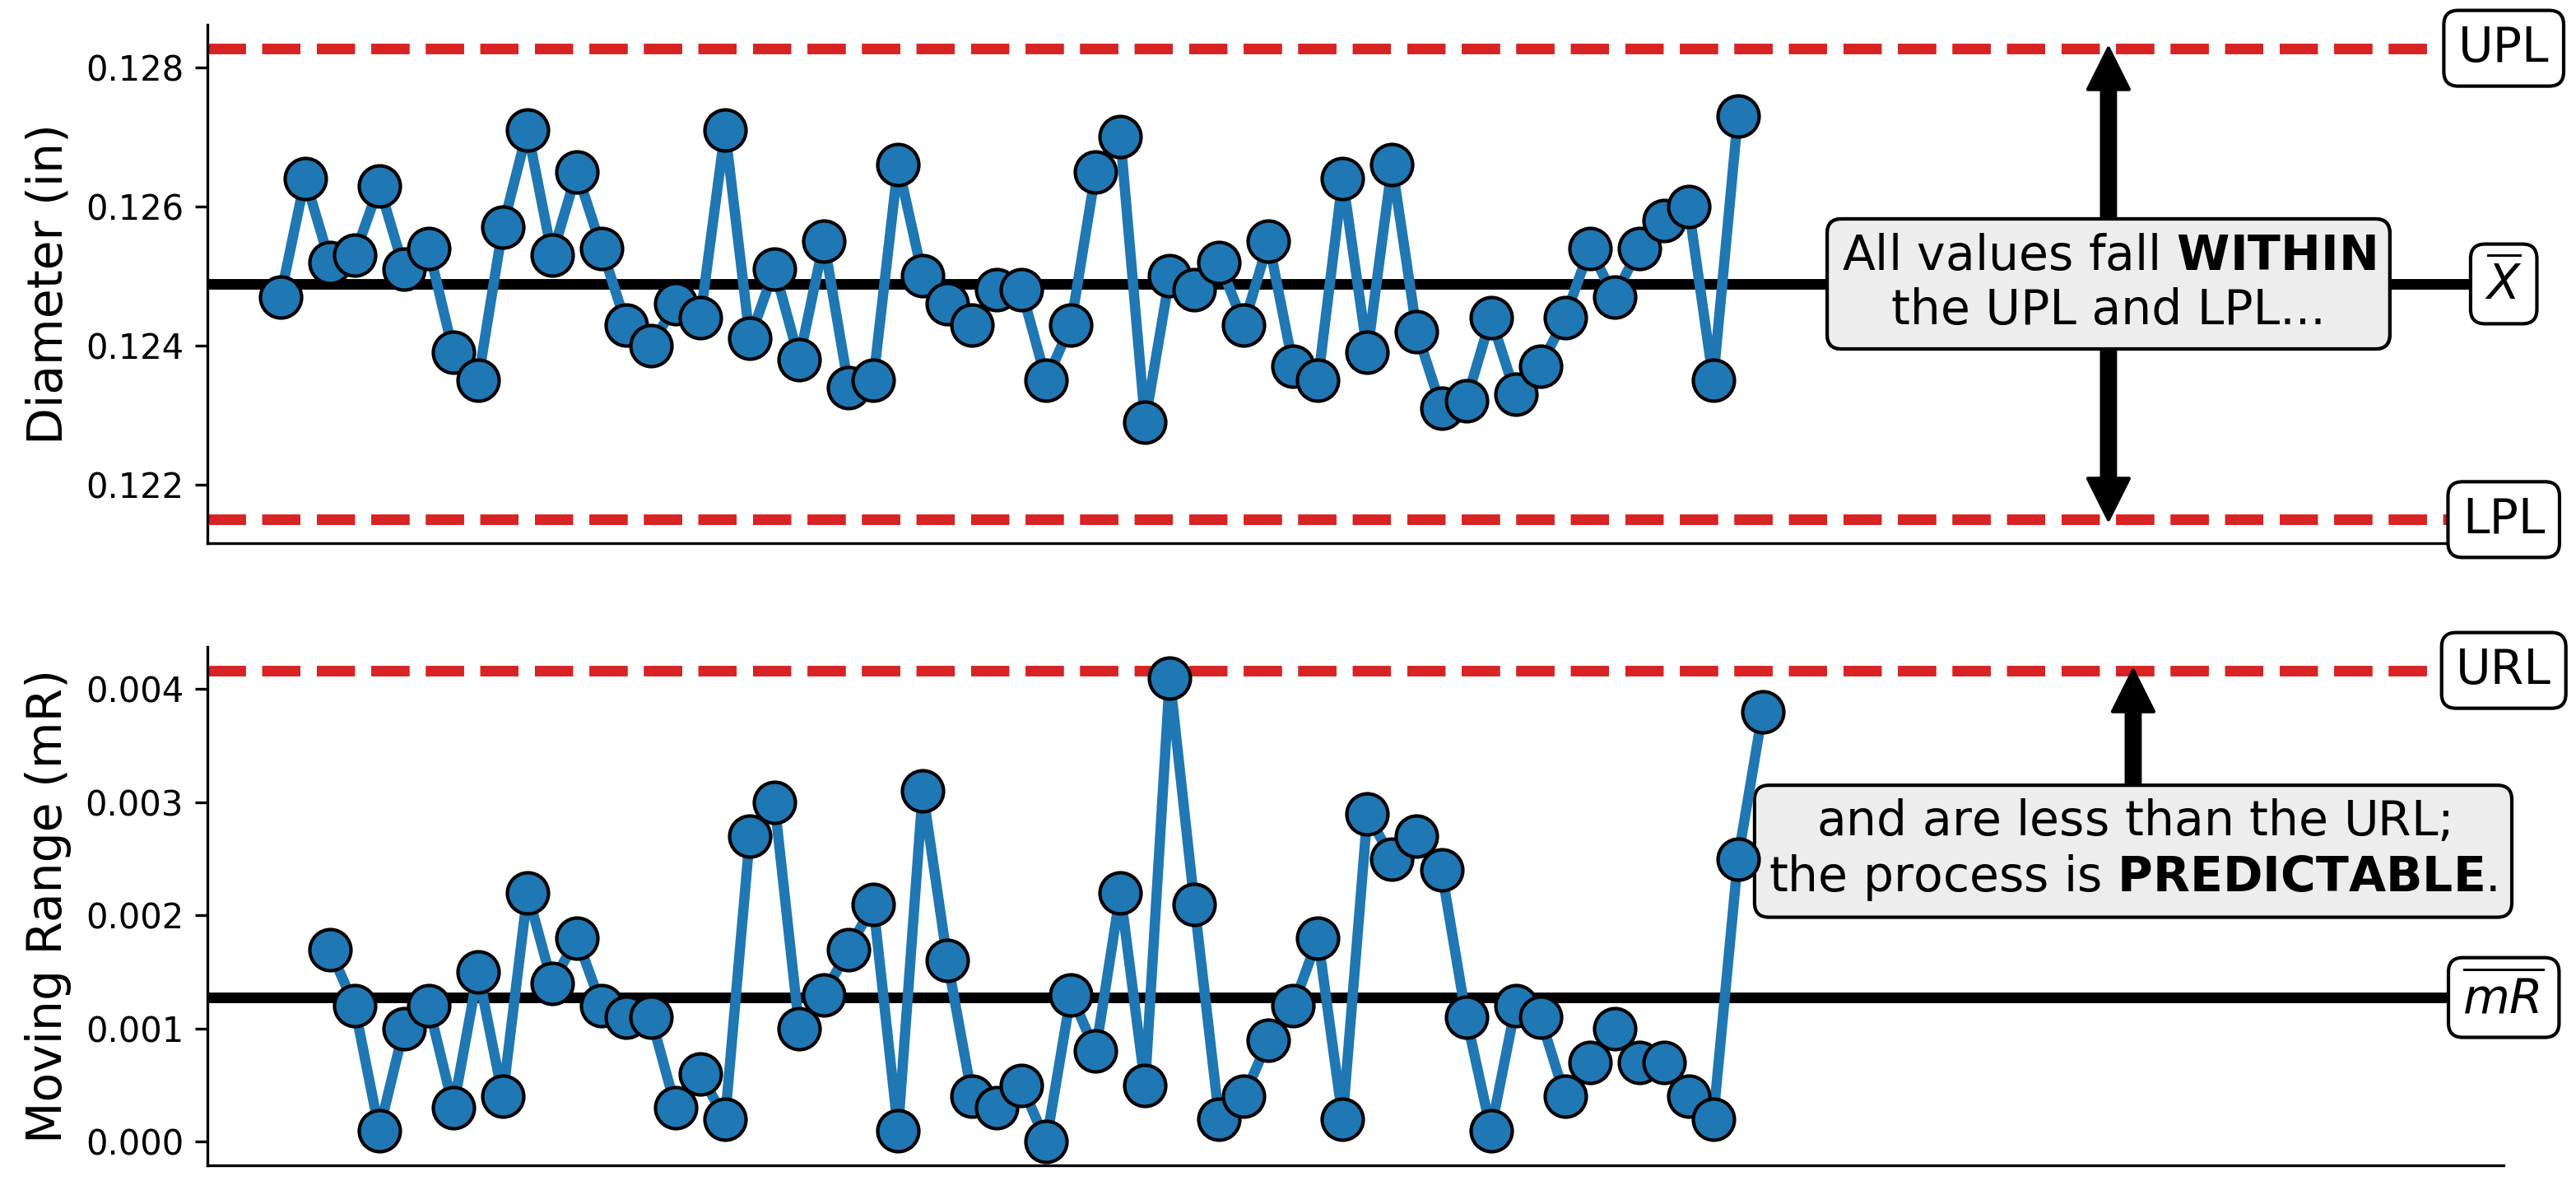

In [40]:
# Create matplotlib figure
fig, axs = plt.subplots(nrows=2, 
                       ncols=1, 
                       figsize=(12,6),
                       dpi=300)

# X chart
axs[0].plot(diameter, 
#             diameter, 
            marker='o', 
            markersize=12,
            markeredgecolor="black",
            linewidth=3,
            zorder=4)

# Specify xticks for x chart
tick_positions = np.arange(1, len(diameter_labels)+1, 4)
axs[0].set_xticks(tick_positions)
axs[0].set_xticklabels(diameter_labels[::4],
                    ha='center', 
                    fontsize=12)

# Extend the x-axis to create room to the right of the data
x_start = axs[0].get_xlim()[0]
x_end = len(diameter_labels) + 30

for ax in axs:
    ax.set_xlim(x_start, x_end)

# Plot X chart limits and center line
for value, line_type, color in diameter_xchart_lines:
    axs[0].axhline(
        value,
        ls=line_type,
        linewidth=3,
        c=color
    )

# Plot mR chart limits and center line
for value, line_type, color in diameter_mrchart_lines:
    axs[1].axhline(
        value,
        ls=line_type,
        linewidth=3,
        c=color
    )

for value, line_type, color in diameter_xchart_lines:
    axs[0].axhline(value, 
                   ls=line_type,
                   linewidth=3,
                   c=color)

# mR chart
axs[1].plot(diameter_labels,
            diameter_mRs, 
            marker='o', 
            markersize=12,
            markeredgecolor="black",
            linewidth=3,
            zorder=4)

for value, line_type, color in diameter_mrchart_lines:
    axs[1].axhline(value, 
                   ls=line_type,
                   linewidth=3,
                   c=color)
    
# Offset moving range by one relative to the indivual values
for xi, yi in zip(diameter_labels, diameter_mRs):
    if np.isnan(yi):
        axs[1].plot(xi, 
                    0, 
                    marker='x', 
                    color='white', 
                    markersize=0) 

# Get x limit of subplots
xlim = axs[0].get_xlim()[1]
mrlim = axs[1].get_xlim()[1]

# Define annotation values
annotations = [
    ("UPL", xlim, diameter_UPL, axs[0]),
    ("LPL", xlim, diameter_LPL, axs[0]),
    ("$\overline{{X}}$", xlim, diameter_mean, axs[0]),
    ("URL", xlim, diameter_URL, axs[1]),
    ("$\overline{{mR}}$", xlim, diameter_ave_mR, axs[1]),
]
        
# Add central line and process limit annotations
for label, x_pos, y_pos, axis in annotations:
    axis.annotate(label,
                 xy=(x_pos, y_pos), 
                 ha="center", 
                 va="center", 
                 fontsize=14, 
                 bbox=dict(
                     facecolor='white', 
                     boxstyle='round')
                )
        
        
# Add y-axis titles
axs[0].set_ylabel("Diameter (in)", 
                  fontsize=14)
axs[1].set_ylabel("Moving Range (mR)", 
                  fontsize=14)

# Remove x and y ticks
for ax in axs:
#     ax.set_yticks([])
    ax.set_xticks([])

# Remove xticks from mR chart
axs[1].set_xticks([])


# Add annotations pointing to both process limits
axs[0].annotate(
    r"All values fall $\mathbf{WITHIN}$" "\n"
    "the UPL and LPL...",
    xy=(74, diameter_UPL),
    xytext=(74, diameter_mean),
    ha='center',
    va='center',
    fontsize=14,
    bbox=dict(facecolor='#EDEDED', boxstyle='round'),
    arrowprops=dict(
        color='black',
        linewidth=1
    )
)

# Add annotations pointing to both process limits
axs[0].annotate(
    r"All values fall $\mathbf{WITHIN}$" "\n"
    "the UPL and LPL...",
    xy=(74, diameter_LPL),
    xytext=(74, diameter_mean),
    ha='center',
    va='center',
    fontsize=14,
    bbox=dict(facecolor='#EDEDED', boxstyle='round'),
    arrowprops=dict(
        color='black',
        linewidth=1
    )
)

# Add annotations pointing to both process limits
axs[1].annotate(
    r"and are $\text{less}\ \text{than}$ the URL;" "\n"
    r"the process is $\mathbf{PREDICTABLE}$.",
    xy=(75, diameter_URL),
    xytext=(75, diameter_ave_mR+0.0013),
    ha='center',
    va='center',
    fontsize=14,
    bbox=dict(facecolor='#EDEDED', boxstyle='round'),
    arrowprops=dict(
        color='black',
        linewidth=1
    )
)
    
# Despine
sns.despine()
    
plt.show()

# Figure 5. Unpredictable Example

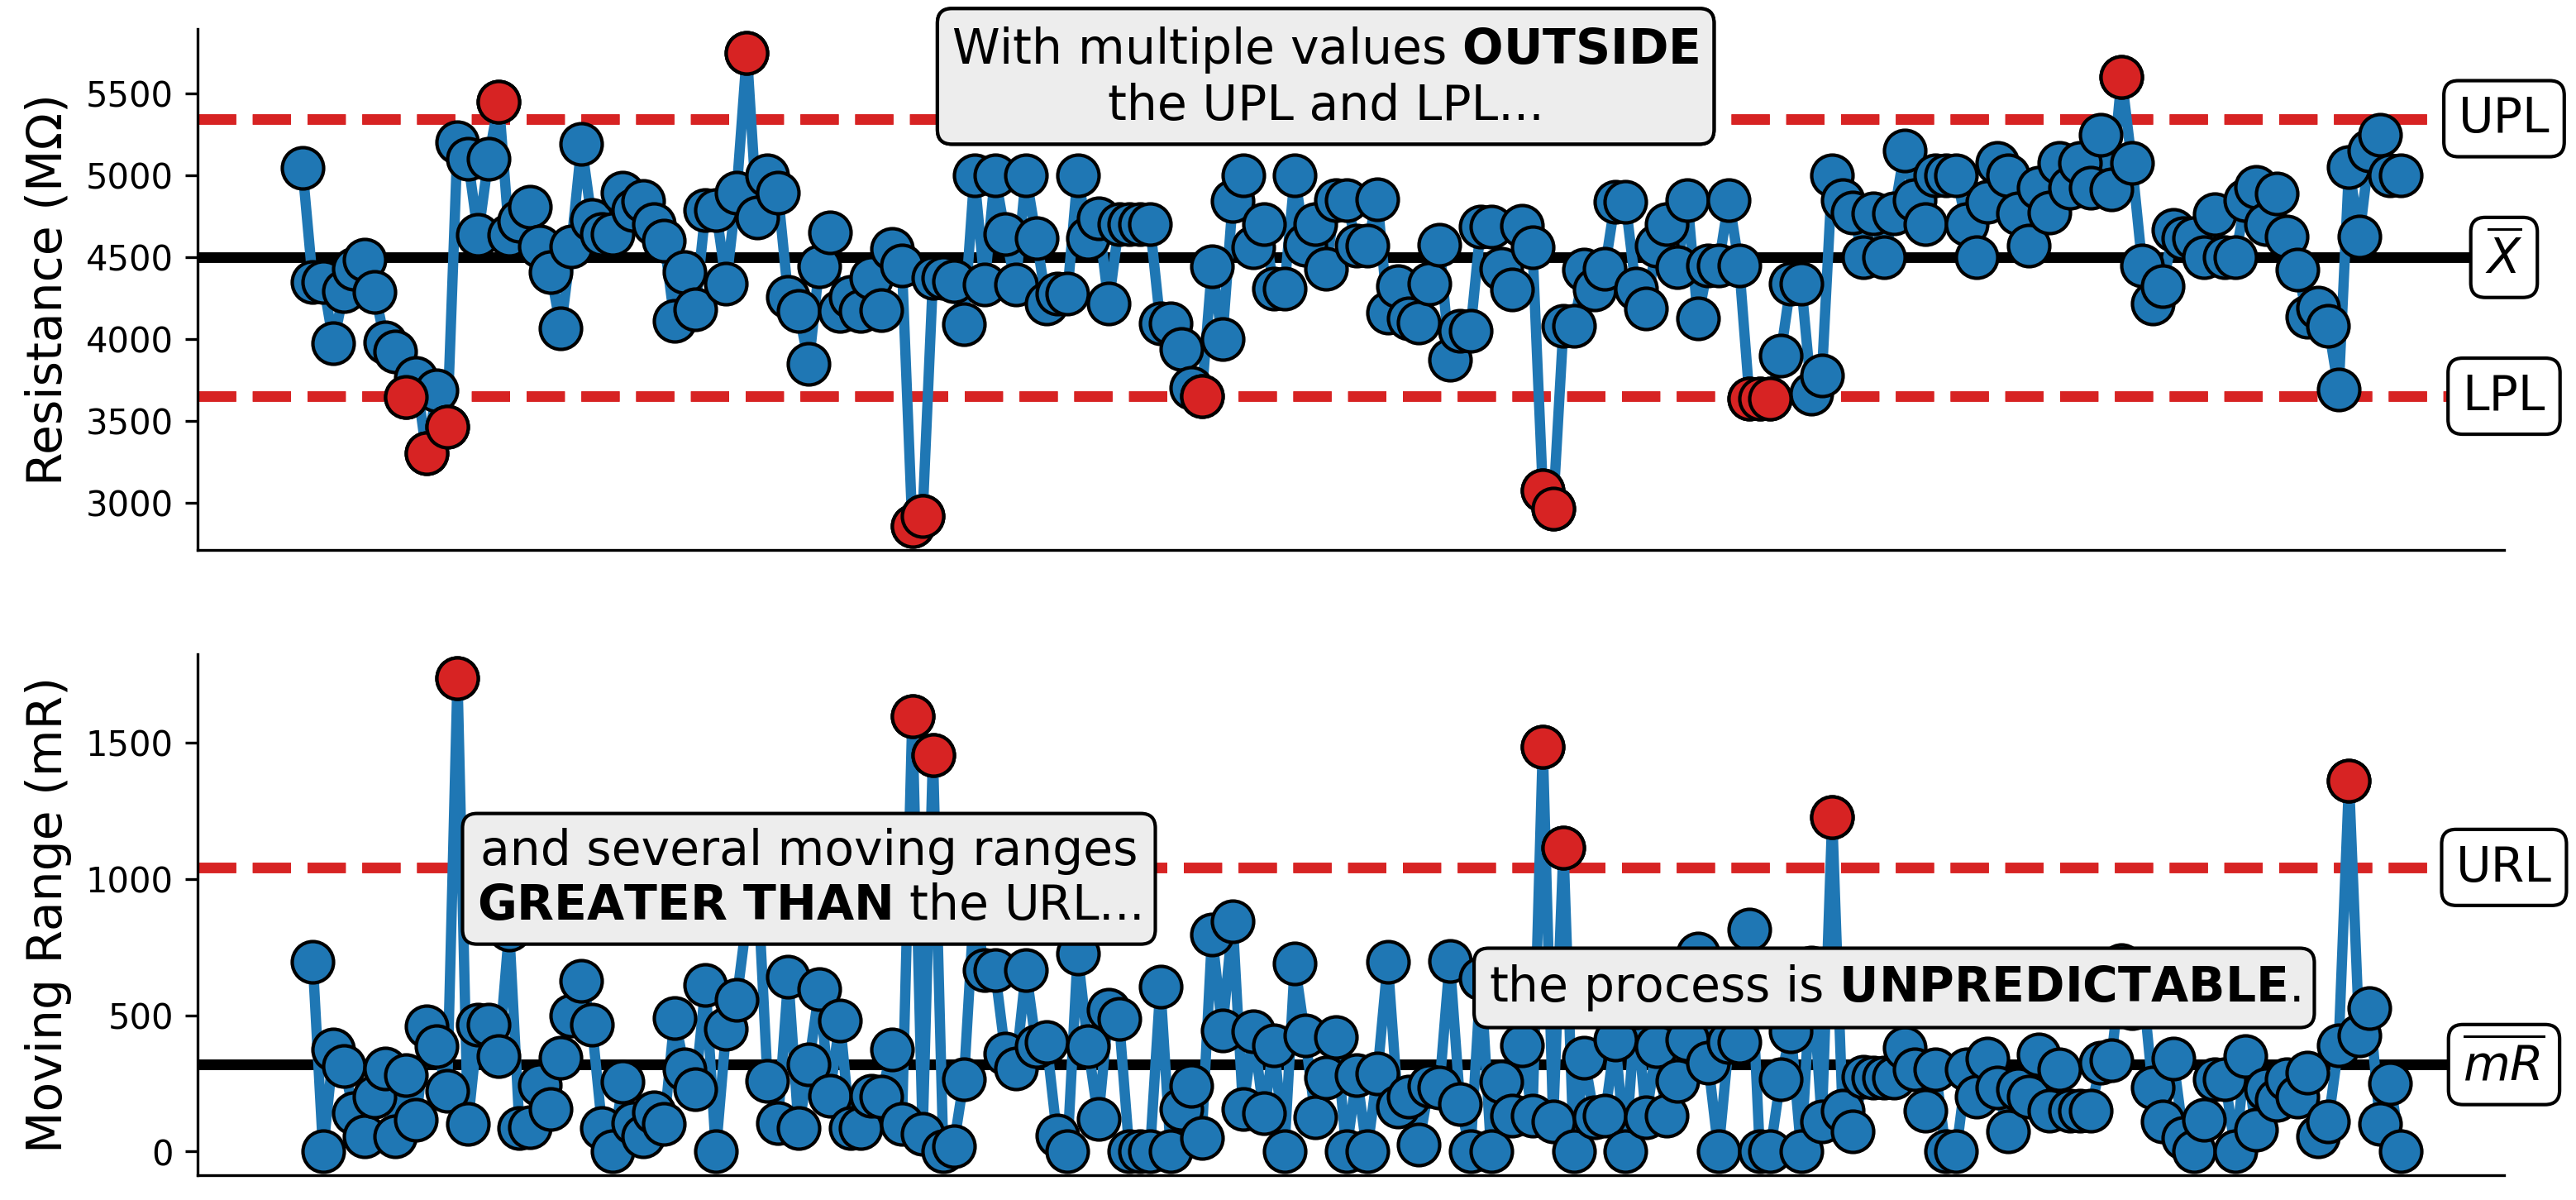

In [41]:
data = resistance_df['Resistance']
mRs = abs(data.diff())
labels = resistance_df['Value']

resistance_stats = xmr_process_stats(data)

mean = resistance_stats['Mean']
ave_mR = resistance_stats['Ave. mR']

UPL = resistance_stats['UPL']
LPL = resistance_stats['LPL']
URL = resistance_stats['URL']

# Specify x chart line parameters
xchart_lines = [
    (mean, "-", "black"),
    (UPL, "--", "#d72323"),
    (LPL, "--", "#d72323")
]

# Specify mR chart parameters
mrchart_lines = [
    (ave_mR, "-", "black"),
    (URL, "--", "#d72323"),
]

# Create matplotlib figure
fig, axs = plt.subplots(nrows=2, 
                       ncols=1, 
                       figsize=(12,6),
                       dpi=300)

# X chart
axs[0].plot(labels, 
            data, 
            marker='o', 
            markersize=12,
            markeredgecolor="black",
            linewidth=3,
            zorder=4)

# Specify assignable cause condition
above_fill_UPL = data > UPL
below_fill_LPL = data < LPL
above_fill_URL = mRs > URL

# Highlight observations above UPL
axs[0].plot(
    labels[above_fill_UPL],
    data[above_fill_UPL],
    marker='o',
    markersize=12,
    markeredgecolor='black',
    markerfacecolor='#d72323',
    linestyle='none',
    zorder=5
)

# Highlight observations below LPL
axs[0].plot(
    labels[below_fill_LPL],
    data[below_fill_LPL],
    marker='o',
    markersize=12,
    markeredgecolor='black',
    markerfacecolor='#d72323',
    linestyle='none',
    zorder=5
)  

# Specify xticks for x chart
tick_positions = np.arange(1, len(labels)+1, 2)
axs[0].set_xticks(tick_positions)
axs[0].set_xticklabels(labels[::2],
                    ha='center', 
                    fontsize=12)

# Extend the x-axis to create room to the right of the data
x_start = axs[0].get_xlim()[0]
x_end = len(labels) + 10

for ax in axs:
    ax.set_xlim(x_start, x_end)

# Plot X chart limits and center line
for value, line_type, color in xchart_lines:
    axs[0].axhline(
        value,
        ls=line_type,
        linewidth=3,
        c=color
    )

# Plot mR chart limits and center line
for value, line_type, color in mrchart_lines:
    axs[1].axhline(
        value,
        ls=line_type,
        linewidth=3,
        c=color
    )

for value, line_type, color in xchart_lines:
    axs[0].axhline(value, 
                   ls=line_type,
                   linewidth=3,
                   c=color)

# mR chart
axs[1].plot(labels,
            mRs, 
            marker='o', 
            markersize=12,
            markeredgecolor="black",
            linewidth=3,
            zorder=4)

# Highlight observations above UPL
axs[1].plot(
    labels[above_fill_URL],
    mRs[above_fill_URL],
    marker='o',
    markersize=12,
    markeredgecolor='black',
    markerfacecolor='#d72323',
    linestyle='none',
    zorder=5
)

for value, line_type, color in mrchart_lines:
    axs[1].axhline(value, 
                   ls=line_type,
                   linewidth=3,
                   c=color)
    
# Offset moving range by one relative to the indivual values
for xi, yi in zip(labels, mRs):
    if np.isnan(yi):
        axs[1].plot(xi, 
                    0, 
                    marker='x', 
                    color='white', 
                    markersize=0) 

# Get x limit of subplots
xlim = axs[0].get_xlim()[1]
mrlim = axs[1].get_xlim()[1]

# Define annotation values
annotations = [
    ("UPL", xlim, UPL, axs[0]),
    ("LPL", xlim, LPL, axs[0]),
    ("$\overline{{X}}$", xlim, mean, axs[0]),
    ("URL", xlim, URL, axs[1]),
    ("$\overline{{mR}}$", xlim, ave_mR, axs[1]),
]
        
# Add central line and process limit annotations
for label, x_pos, y_pos, axis in annotations:
    axis.annotate(label,
                 xy=(x_pos, y_pos), 
                 ha="center", 
                 va="center", 
                 fontsize=14, 
                 bbox=dict(
                     facecolor='white', 
                     boxstyle='round')
                )
        
        
# Add y-axis titles
axs[0].set_ylabel("Resistance (MΩ)", 
                  fontsize=14)
axs[1].set_ylabel("Moving Range (mR)", 
                  fontsize=14)

# Remove x and y ticks
# for ax in axs:
#     ax.set_yticks([])

# Remove xticks from mR chart
axs[1].set_xticks([])

# Annotation text and formatting
annotation_text_xchart = (
    r"With multiple values $\mathbf{OUTSIDE}$" "\n"
    "the UPL and LPL..."
)

annotation_text_mrchart = (
    r"and several moving ranges" "\n" "$\mathbf{GREATER}\ \mathbf{THAN}$ the URL..."
)

# Add annotations pointing to both process limits
for limit in [UPL - 0.02, LPL + 0.02]:
    axs[0].annotate(
        annotation_text_xchart,
        xy=(100, 5600),
        ha='center',
        va='center',
        fontsize=14,
        bbox=dict(facecolor='#EDEDED', boxstyle='round'),
        arrowprops=dict(
            color='black',
            linewidth=1
        )
    )
    
# Add annotations pointing to both process limits
axs[1].annotate(
    r"and several moving ranges" "\n" "$\mathbf{GREATER}\ \mathbf{THAN}$ the URL...",
    xy=(50, 1000),
    ha='center',
    va='center',
    fontsize=14,
    bbox=dict(facecolor='#EDEDED', boxstyle='round'),
    arrowprops=dict(
        color='black',
        linewidth=1
    ),
    zorder=5
)
    

axs[1].annotate(
    "the process is $\mathbf{UNPREDICTABLE}$.",
    xy=(155, 600),
    ha='center',
    va='center',
    fontsize=14,
    bbox=dict(facecolor='#EDEDED', boxstyle='round'),
    arrowprops=dict(
        color='black',
        linewidth=1
    ),
    zorder=5
)
    
    
# Despine
sns.despine()

axs[0].set_xticks([])
    
plt.show()

# Figure 6. Process Histogram Examples

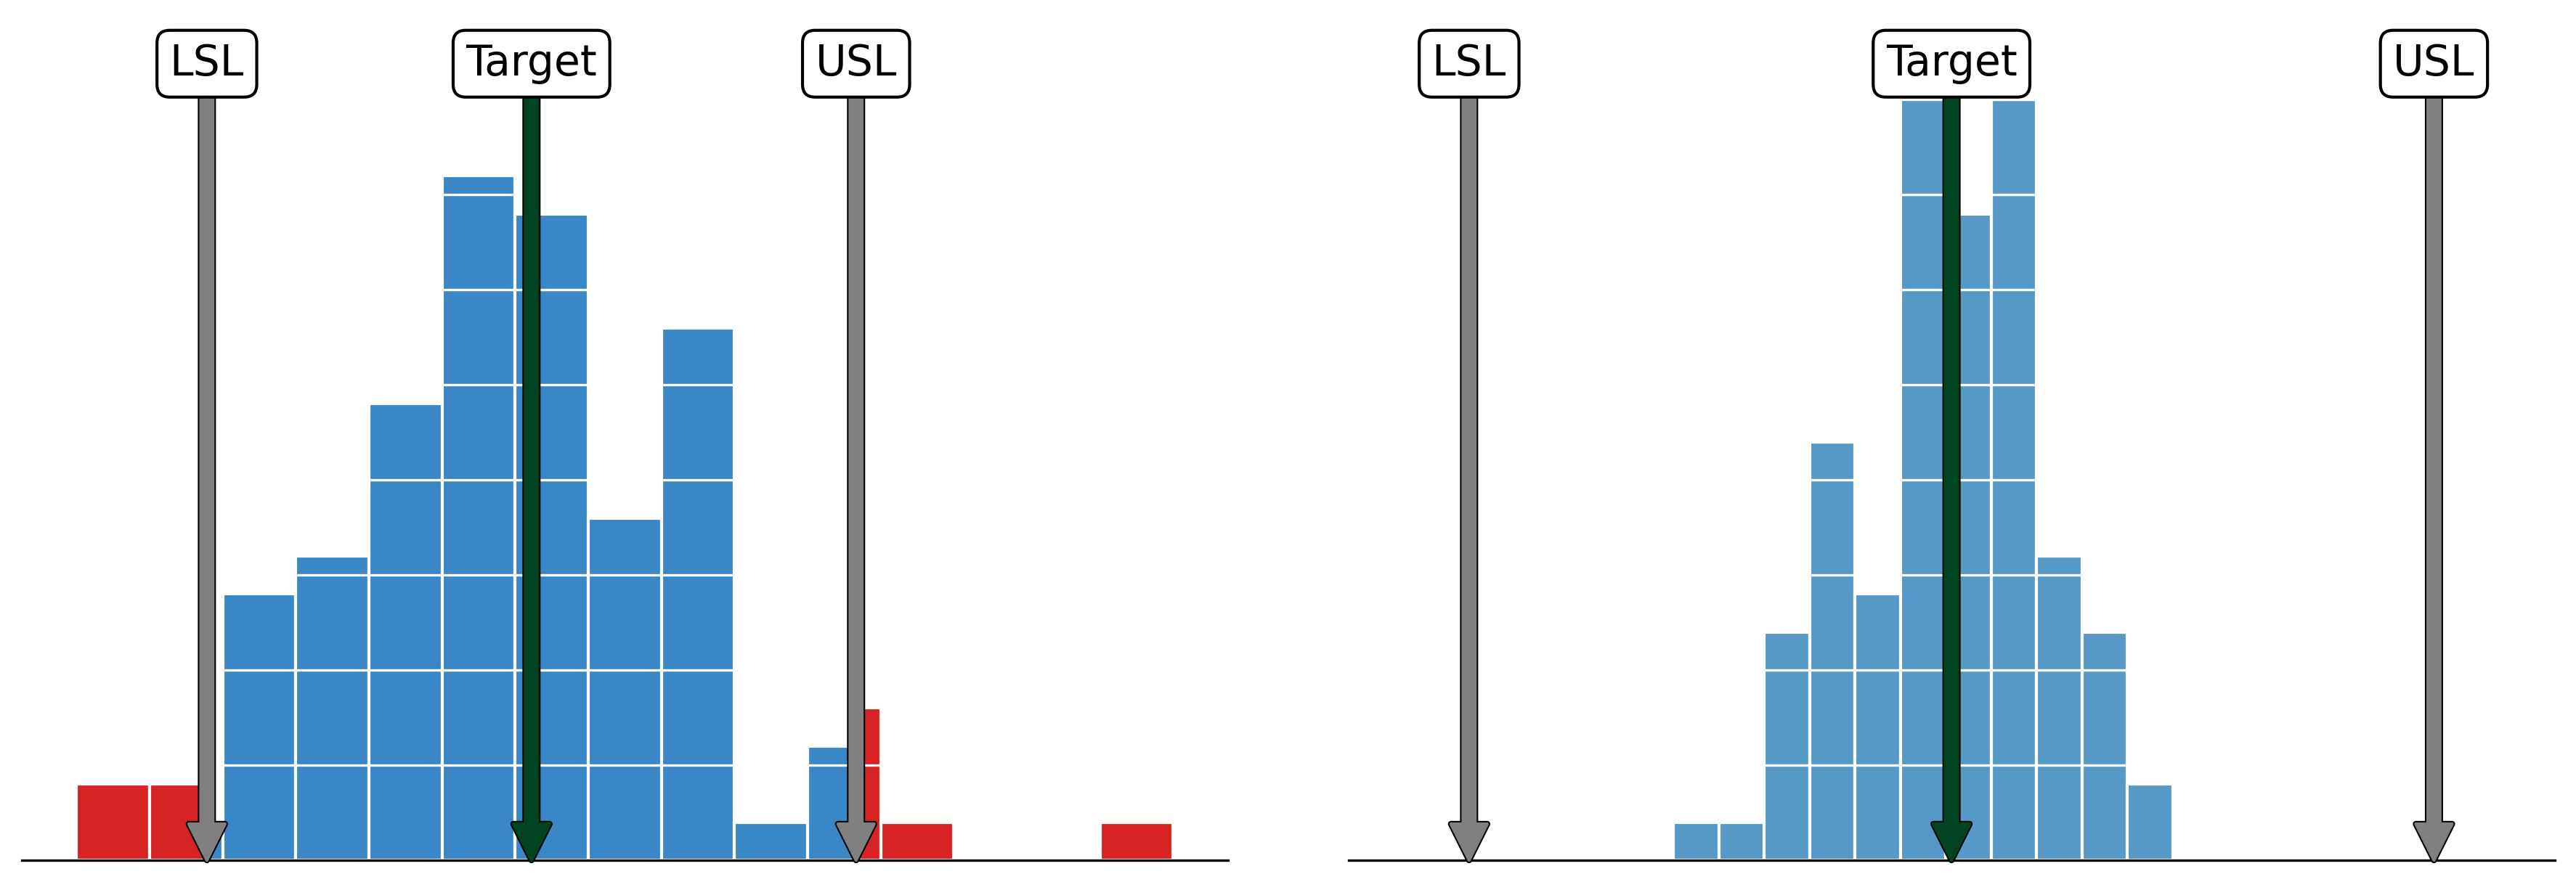

In [142]:
USL = 12
LSL = 8
Target = 10

# --- GENERATE RANDOM NORMAL DATA ---
np.random.seed(40)

narrow = np.random.normal(
    loc=10,
    scale=0.4,
    size=100
)

wide = np.random.normal(
    loc=10,
    scale=1.15,
    size=100
)

# --- CREATE FIGURE ---
fig, axs = plt.subplots(
    figsize=(15, 5),
    nrows=1,
    ncols=2,
    sharey=True,
    dpi=300
)

plt.subplots_adjust(wspace=0.1)

# Wide Histogram
bin_edges = np.histogram_bin_edges(wide, bins=15)
bin_edges = np.unique(np.r_[bin_edges, LSL, USL])

counts, edges = np.histogram(wide, bins=bin_edges)

for count, left, right in zip(counts, edges[:-1], edges[1:]):
    color = '#d72323' if right <= LSL or left >= USL else '#3A87C8'

    axs[0].bar(
        left,
        count,
        width=right - left,
        align='edge',
        color=color,
        edgecolor='white'
    )

# Narrow Histogram
sns.histplot(
    x=narrow,
    edgecolor='white',
    ax=axs[1]
)

# Define annotation values
annotations = [
    ("USL", USL, '#808080'),
    ("LSL", LSL, '#808080'),
    ("Target", Target, '#014421')
]

# Add annotations to both histograms
for ax in axs:
    for label, x_pos, color in annotations:
        ax.annotate(
            label,
            xy=(x_pos, 0),
            xycoords='data',
            xytext=(x_pos, 0.95),
            textcoords=('data', 'axes fraction'),
            ha="center",
            va="center",
            fontsize=14,
            bbox=dict(
                facecolor='white',
                edgecolor='black',
                boxstyle='round'
            ),
            arrowprops=dict(
                color=color,
                lw=1,
                path_effects=[
                    pe.Stroke(linewidth=2, foreground='black'),
                    pe.Normal()
                ]
            )
        )

axs[1].set_xlim(left=7.5, right=12.5)

for ax in axs:
    ax.tick_params(axis='y', left=False, labelleft=False)
    ax.tick_params(axis='x', bottom=False, labelbottom=False)
    ax.grid(axis='y', color='white')

axs[0].set_ylabel('')

sns.despine(left=True)
plt.show()

# Figure 7. Off Target Process Histogram Example

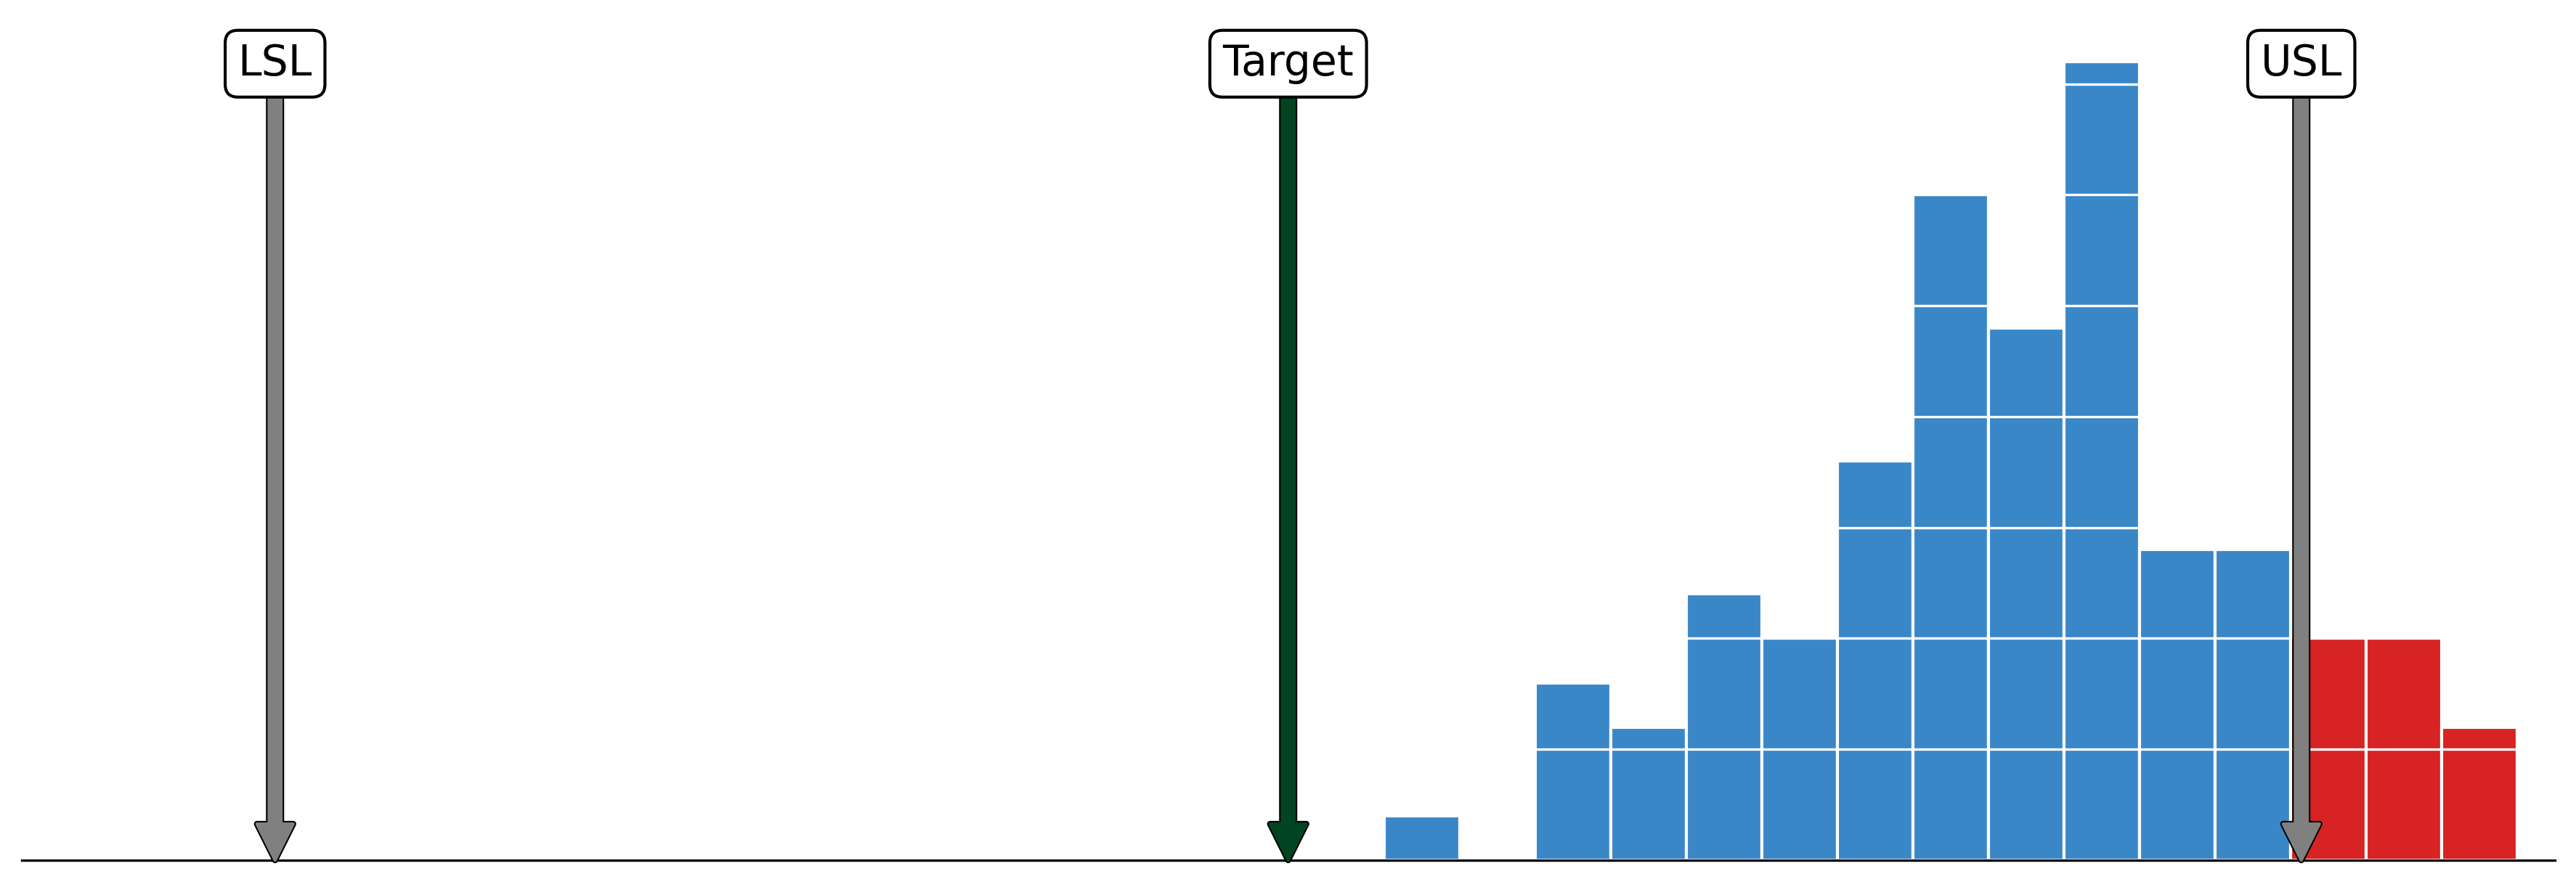

In [144]:
USL = 12
LSL = 8
Target = 10

# --- GENERATE RANDOM NORMAL DATASET ---
np.random.seed(42)

narrow_off_center = np.random.normal(
    loc=11.5,
    scale=0.5,
    size=100
)

# --- CREATE FIGURE ---
fig, ax = plt.subplots(
    figsize=(15, 5),
    dpi=300
)

# Generate histogram data
counts, bin_edges = np.histogram(
    narrow_off_center,
    bins=15
)

# Draw histogram bars, splitting bins at USL
for count, left, right in zip(counts, bin_edges[:-1], bin_edges[1:]):

    if right <= USL:
        ax.bar(
            left, count,
            width=right - left,
            align='edge',
            color='#3A87C8',
            edgecolor='white'
        )

    elif left >= USL:
        ax.bar(
            left, count,
            width=right - left,
            align='edge',
            color='#d72323',
            edgecolor='white'
        )

    else:
        # Portion below USL
        ax.bar(
            left, count,
            width=USL - left,
            align='edge',
            color='#d72323',
            edgecolor='white'
        )

        # Portion above USL
        ax.bar(
            USL, count,
            width=right - USL,
            align='edge',
            color='#d72323',
            edgecolor='white'
        )


# Annotations
annotations = [
    ("USL", USL, '#808080'),
    ("LSL", LSL, '#808080'),
    ("Target", Target, '#014421')
]

for label, x_pos, color in annotations:
    ax.annotate(
        label,
        xy=(x_pos, 0),
        xycoords='data',
        xytext=(x_pos, 0.95),
        textcoords=('data', 'axes fraction'),
        ha="center",
        va="center",
        fontsize=14,
        bbox=dict(
            facecolor='white',
            edgecolor='black',
            boxstyle='round'
        ),
        arrowprops=dict(
            color=color,
            lw=1,
            path_effects=[
                pe.Stroke(linewidth=2, foreground='black'),
                pe.Normal()
            ]
        )
    )

ax.set_xlim(7.5, 12.5)
ax.set_ylabel('')
ax.set_xticks([])

ax.tick_params(axis='y', left=False, labelleft=False)
ax.grid(axis='y', color='white')

sns.despine(left=True)
plt.show()

# Figure 8. XmR Chart with Process Hist

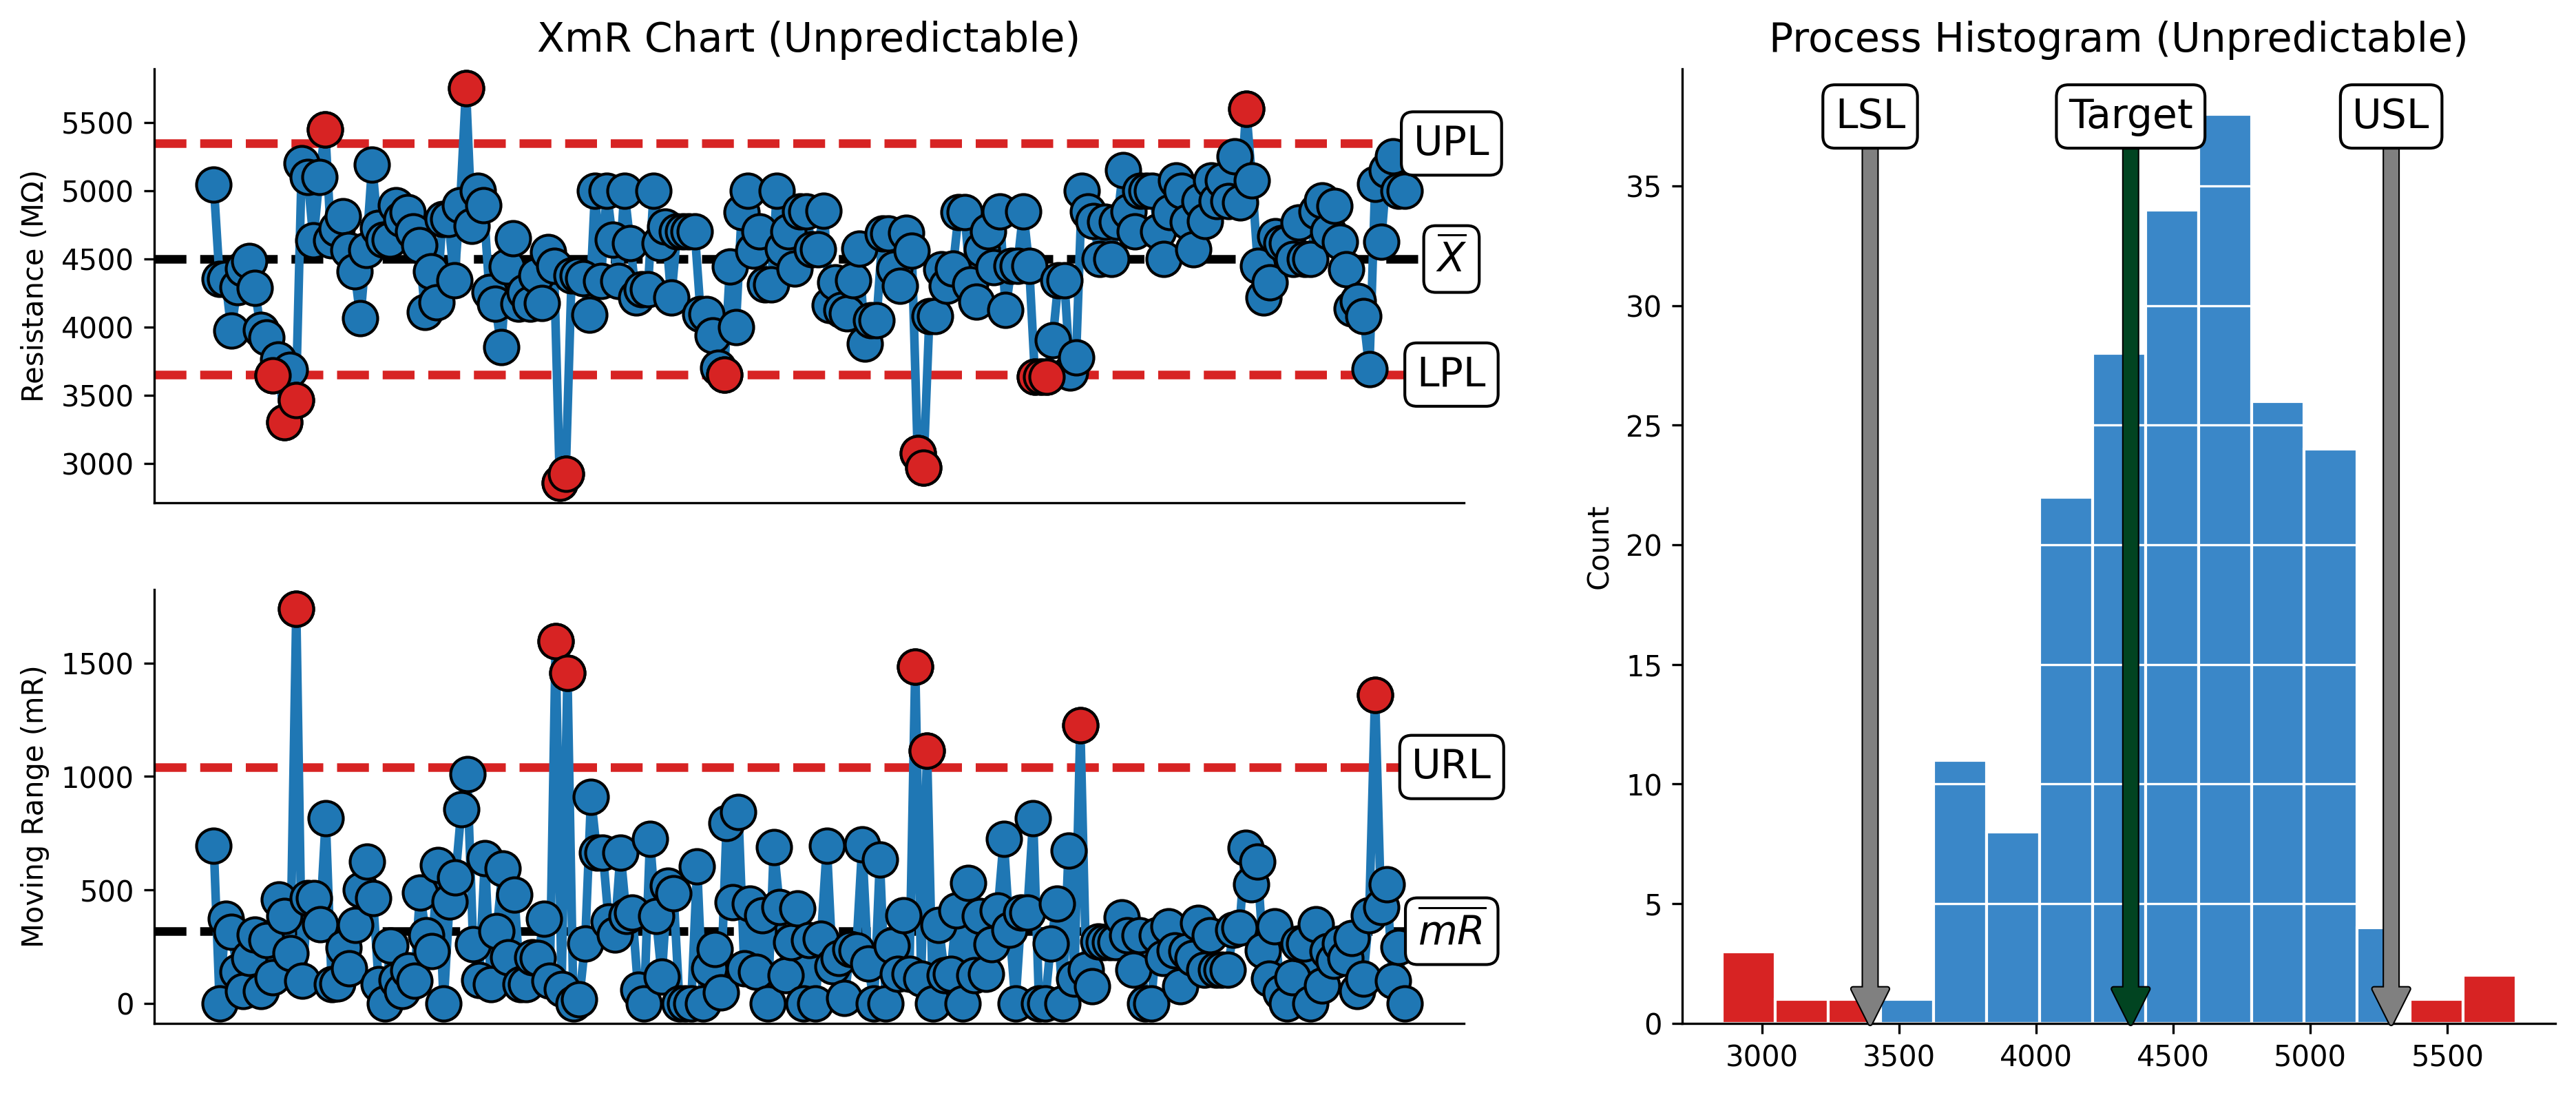

In [170]:
data = resistance_df['Resistance']
mRs = abs(data.diff())

resistance_stats = xmr_process_stats(data)

resistance_mean = resistance_stats['Mean']
resistance_ave_mR = resistance_stats['Ave. mR']

resistance_UPL = resistance_stats['UPL']
resistance_LPL = resistance_stats['LPL']
resistance_URL = resistance_stats['URL']

USL = 5295
LSL = 3395
Target = 4345

fig = plt.figure(figsize=(15, 6), dpi=300)

gs = fig.add_gridspec(
    2, 2,
    width_ratios=[1.5, 1]
)

# First column: two rows
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0])

# Second column: spans both rows
ax3 = fig.add_subplot(gs[:, 1])

x = np.arange(1, len(data) + 1)

# Plot the X chart
ax1.plot(
    x,
    data,
    marker='o', 
            markersize=12,
            markeredgecolor="black",
            linewidth=3,
            zorder=4)

xchart_lines = [
    (resistance_UPL, '#d72323'),
    (resistance_LPL, '#d72323'),
    (resistance_mean, 'black')
]

mRchart_lines = [
    (resistance_URL, '#d72323'),
    (resistance_ave_mR, 'black')
]

for value, line_color in xchart_lines:
    ax1.axhline(
        value,
        color=line_color,
        ls='--',
        lw=3
    )
        
for value, line_color in mRchart_lines:
    ax2.axhline(
        value,
        color=line_color,
        ls='--',
        lw=3
    )

# Plot the X chart
ax2.plot(
    x[1:],
    mRs.iloc[1:], 
            marker='o', 
            markersize=12,
            markeredgecolor="black",
            linewidth=3,
            zorder=4)

# Specify assignable cause condition
above_fill_UPL = data > resistance_UPL
below_fill_LPL = data < resistance_LPL
above_fill_URL = mRs > resistance_URL

# Highlight observations greater than UPL
ax1.plot(
    x[above_fill_UPL],
    data[above_fill_UPL],
    marker='o',
    markersize=12,
    markeredgecolor='black',
    markerfacecolor='#d72323',
    linestyle='none',
    zorder=5
)

# Highlight observations less than LPL
ax1.plot(
    x[below_fill_LPL],
    data[below_fill_LPL],
    marker='o',
    markersize=12,
    markeredgecolor='black',
    markerfacecolor='#d72323',
    linestyle='none',
    zorder=5
)

# Highlight observations greater than URL
ax2.plot(
    x[above_fill_URL],
    mRs[above_fill_URL],
    marker='o',
    markersize=12,
    markeredgecolor='black',
    markerfacecolor='#d72323',
    linestyle='none',
    zorder=5
)


# Plot the histogram
bin_edges = np.histogram_bin_edges(data, bins=15)
bin_edges = np.unique(np.r_[bin_edges, LSL, USL])

counts, edges = np.histogram(data, bins=bin_edges)

for count, left, right in zip(counts, edges[:-1], edges[1:]):
    color = '#d72323' if right <= LSL or left >= USL else '#3A87C8'

    ax3.bar(
        left,
        count,
        width=right - left,
        align='edge',
        color=color,
        edgecolor='white'
    )

# Define XmR chart annotations
xchart_annotations = [
    ("UPL", resistance_UPL, '#d72323'),
    ("LPL", resistance_LPL, '#d72323'),
    ("$\overline{{X}}$", resistance_mean, 'black')
]

mRchart_annotations = [
    ("URL", resistance_URL, '#d72323'),
    ("$\overline{{mR}}$", resistance_ave_mR, 'black')
]

# Add annotations to histogram
for label, y_pos, color in xchart_annotations:
    ax1.annotate(
        label,
        xy=(212, y_pos),
        ha="center",
        va="center",
        fontsize=14,
        bbox=dict(
            facecolor='white',
            edgecolor='black',
            boxstyle='round'
        ),
        zorder=5
    )
    
# Add annotations to histogram
for label, y_pos, color in mRchart_annotations:
    ax2.annotate(
        label,
        xy=(212, y_pos),
        ha="center",
        va="center",
        fontsize=14,
        bbox=dict(
            facecolor='white',
            edgecolor='black',
            boxstyle='round'
        ),
        zorder=5
    )

# Define annotation values
hist_annotations = [
    ("USL", USL, '#808080'),
    ("LSL", LSL, '#808080'),
    ("Target", Target, '#014421')
]

# Add annotations to histogram
for label, x_pos, color in hist_annotations:
    ax3.annotate(
        label,
        xy=(x_pos, 0),
        xycoords='data',
        xytext=(x_pos, 0.95),
        textcoords=('data', 'axes fraction'),
        ha="center",
        va="center",
        fontsize=14,
        bbox=dict(
            facecolor='white',
            edgecolor='black',
            boxstyle='round'
        ),
        arrowprops=dict(
            color=color,
            lw=1,
            path_effects=[
                pe.Stroke(linewidth=2, foreground='black'),
                pe.Normal()
            ]
        )
    )

    
ax1.set_xticks([])
ax2.set_xticks([])

ax3.set_ylabel('Count')
ax3.grid(axis='y', color='white')

ax1.set_ylabel('Resistance (MΩ)')
ax2.set_ylabel('Moving Range (mR)')

ax1.set_title('XmR Chart (Unpredictable)', fontsize=14)
ax3.set_title('Process Histogram (Unpredictable)', fontsize=14)

sns.despine()

plt.show()

# Figure 9. Machine 2 Combo Chart

(<Figure size 3600x1800 with 2 Axes>,
 array([<Axes: title={'center': 'X Chart'}>,
        <Axes: title={'center': 'Process Histogram'}>], dtype=object))

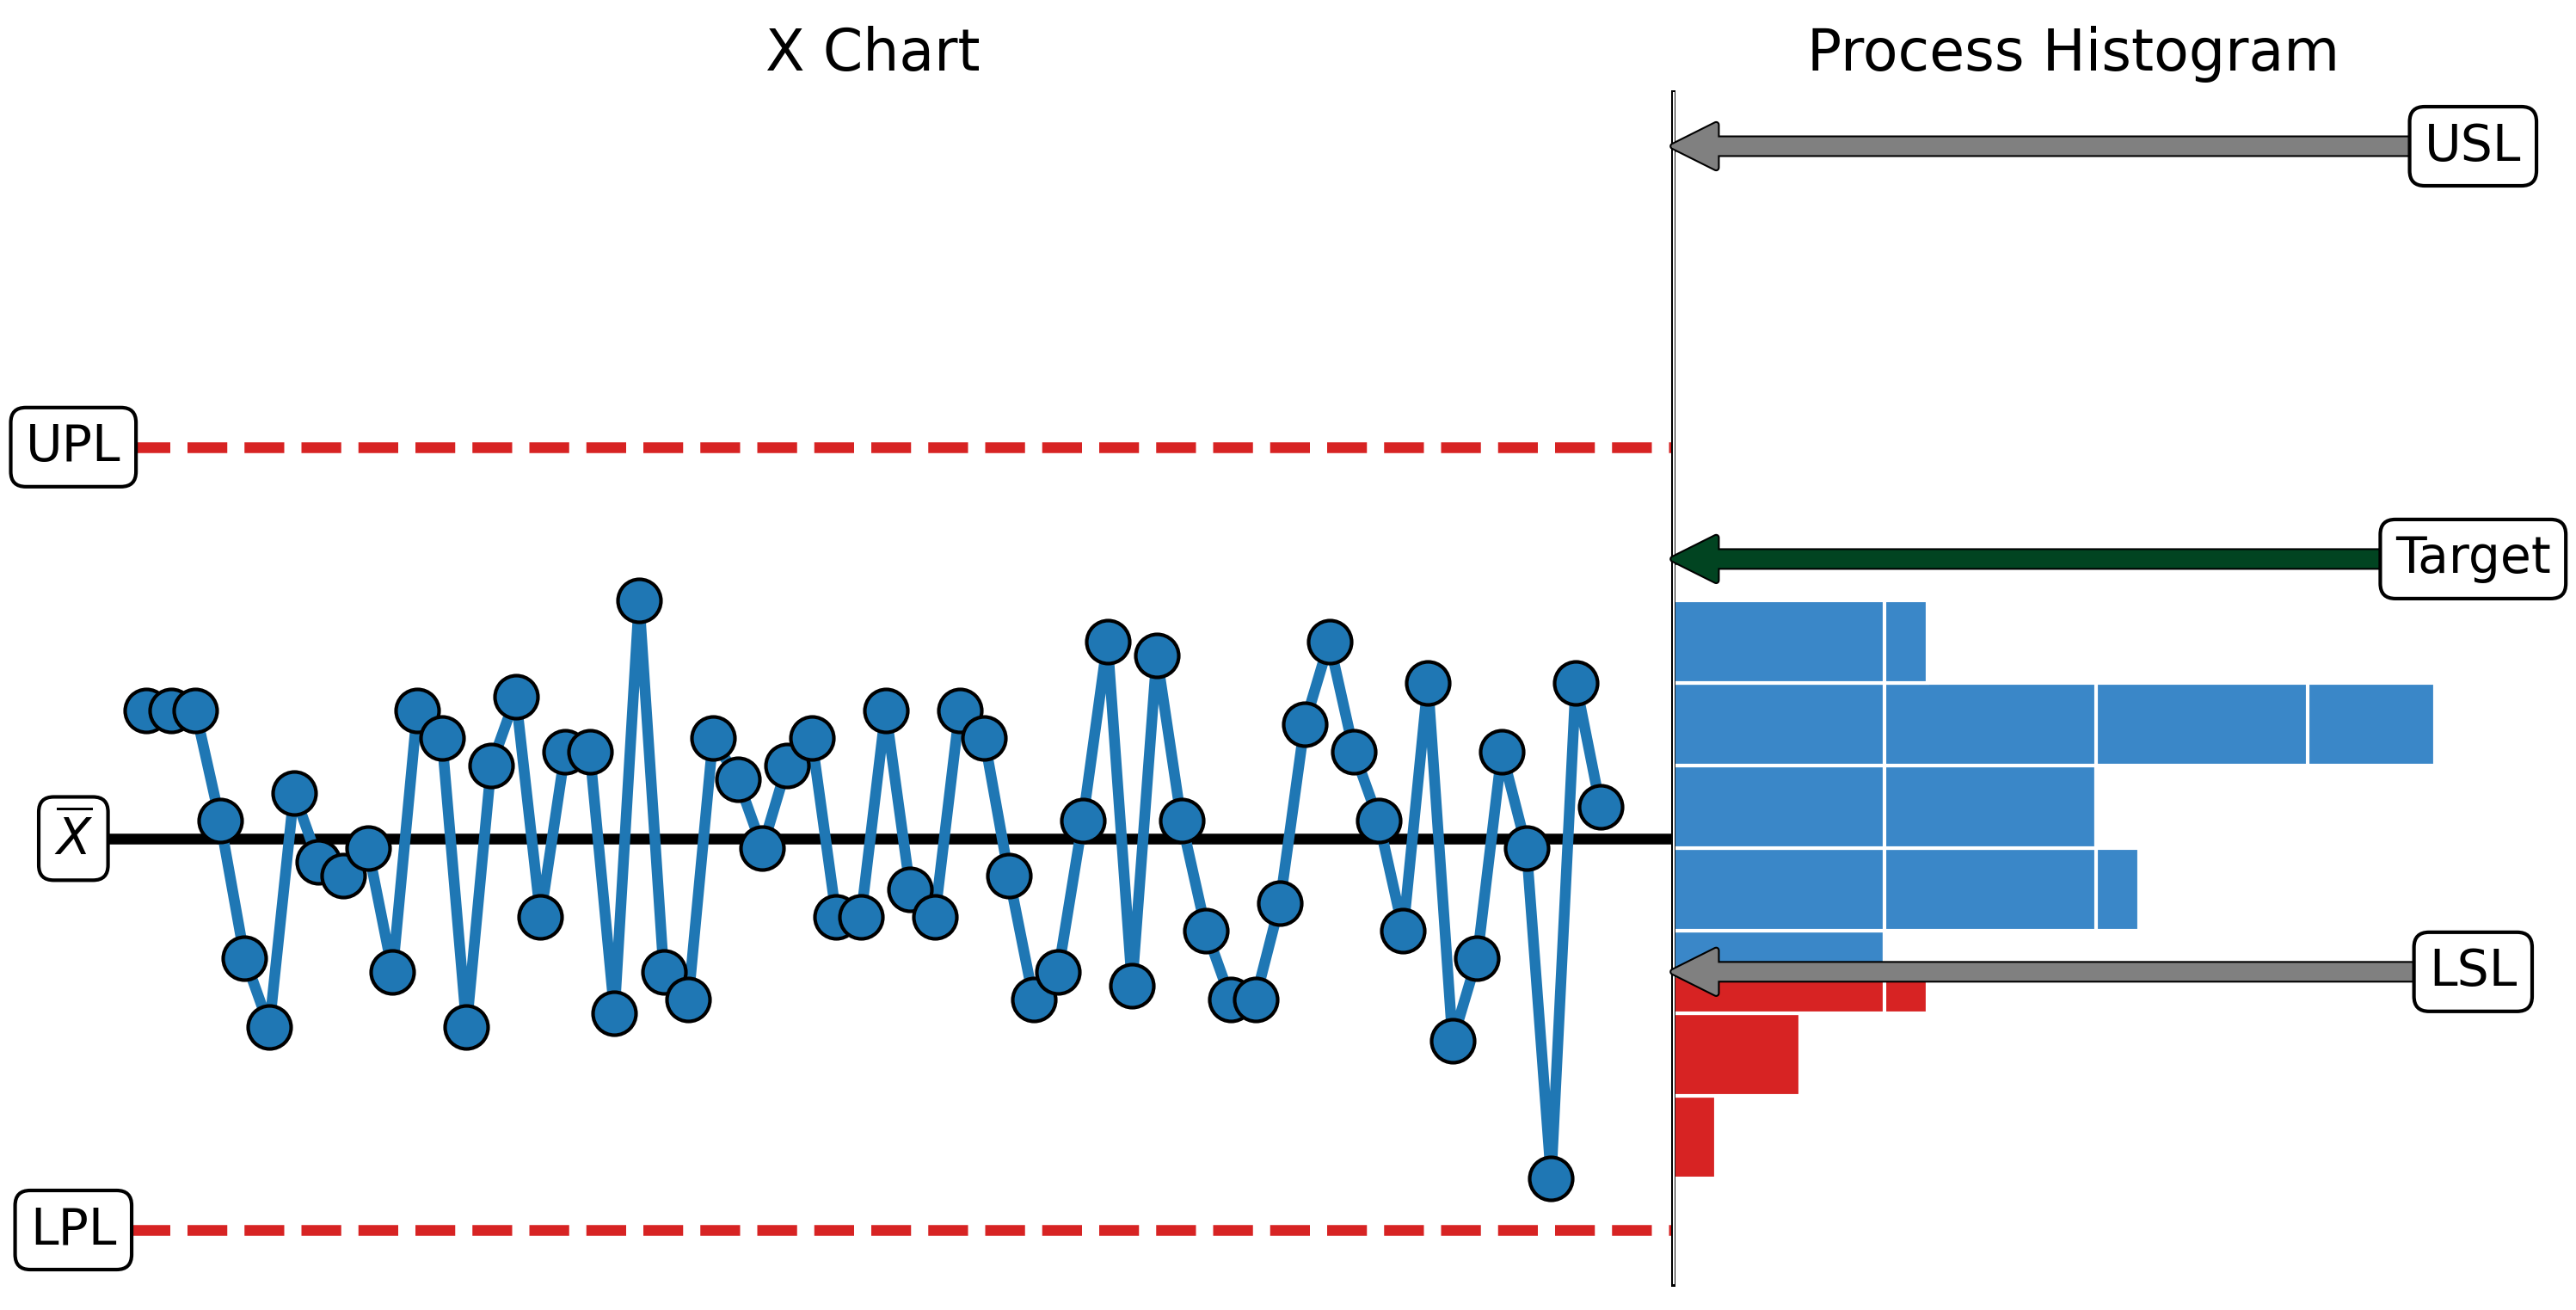

In [155]:
machine_screw_2_df['Sample'] = np.arange(1, len(machine_screw_2_df) + 1)
machine_screw_2_df = machine_screw_2_df.drop(columns=['MACHINE', 'DAY', 'SAMPLE', 'TIME (1 = AM, 2 = PM)'])

data = machine_screw_2_df['DIAMETER (in)']
labels = machine_screw_2_df['Sample']

USL = 0.128
LSL = 0.122
Target = 0.125

combo_chart(data, labels, USL, LSL, Target)

# Figure 10. Machine 3 Practical Example

(<Figure size 3600x1800 with 2 Axes>,
 array([<Axes: title={'center': 'X Chart'}>,
        <Axes: title={'center': 'Process Histogram'}>], dtype=object))

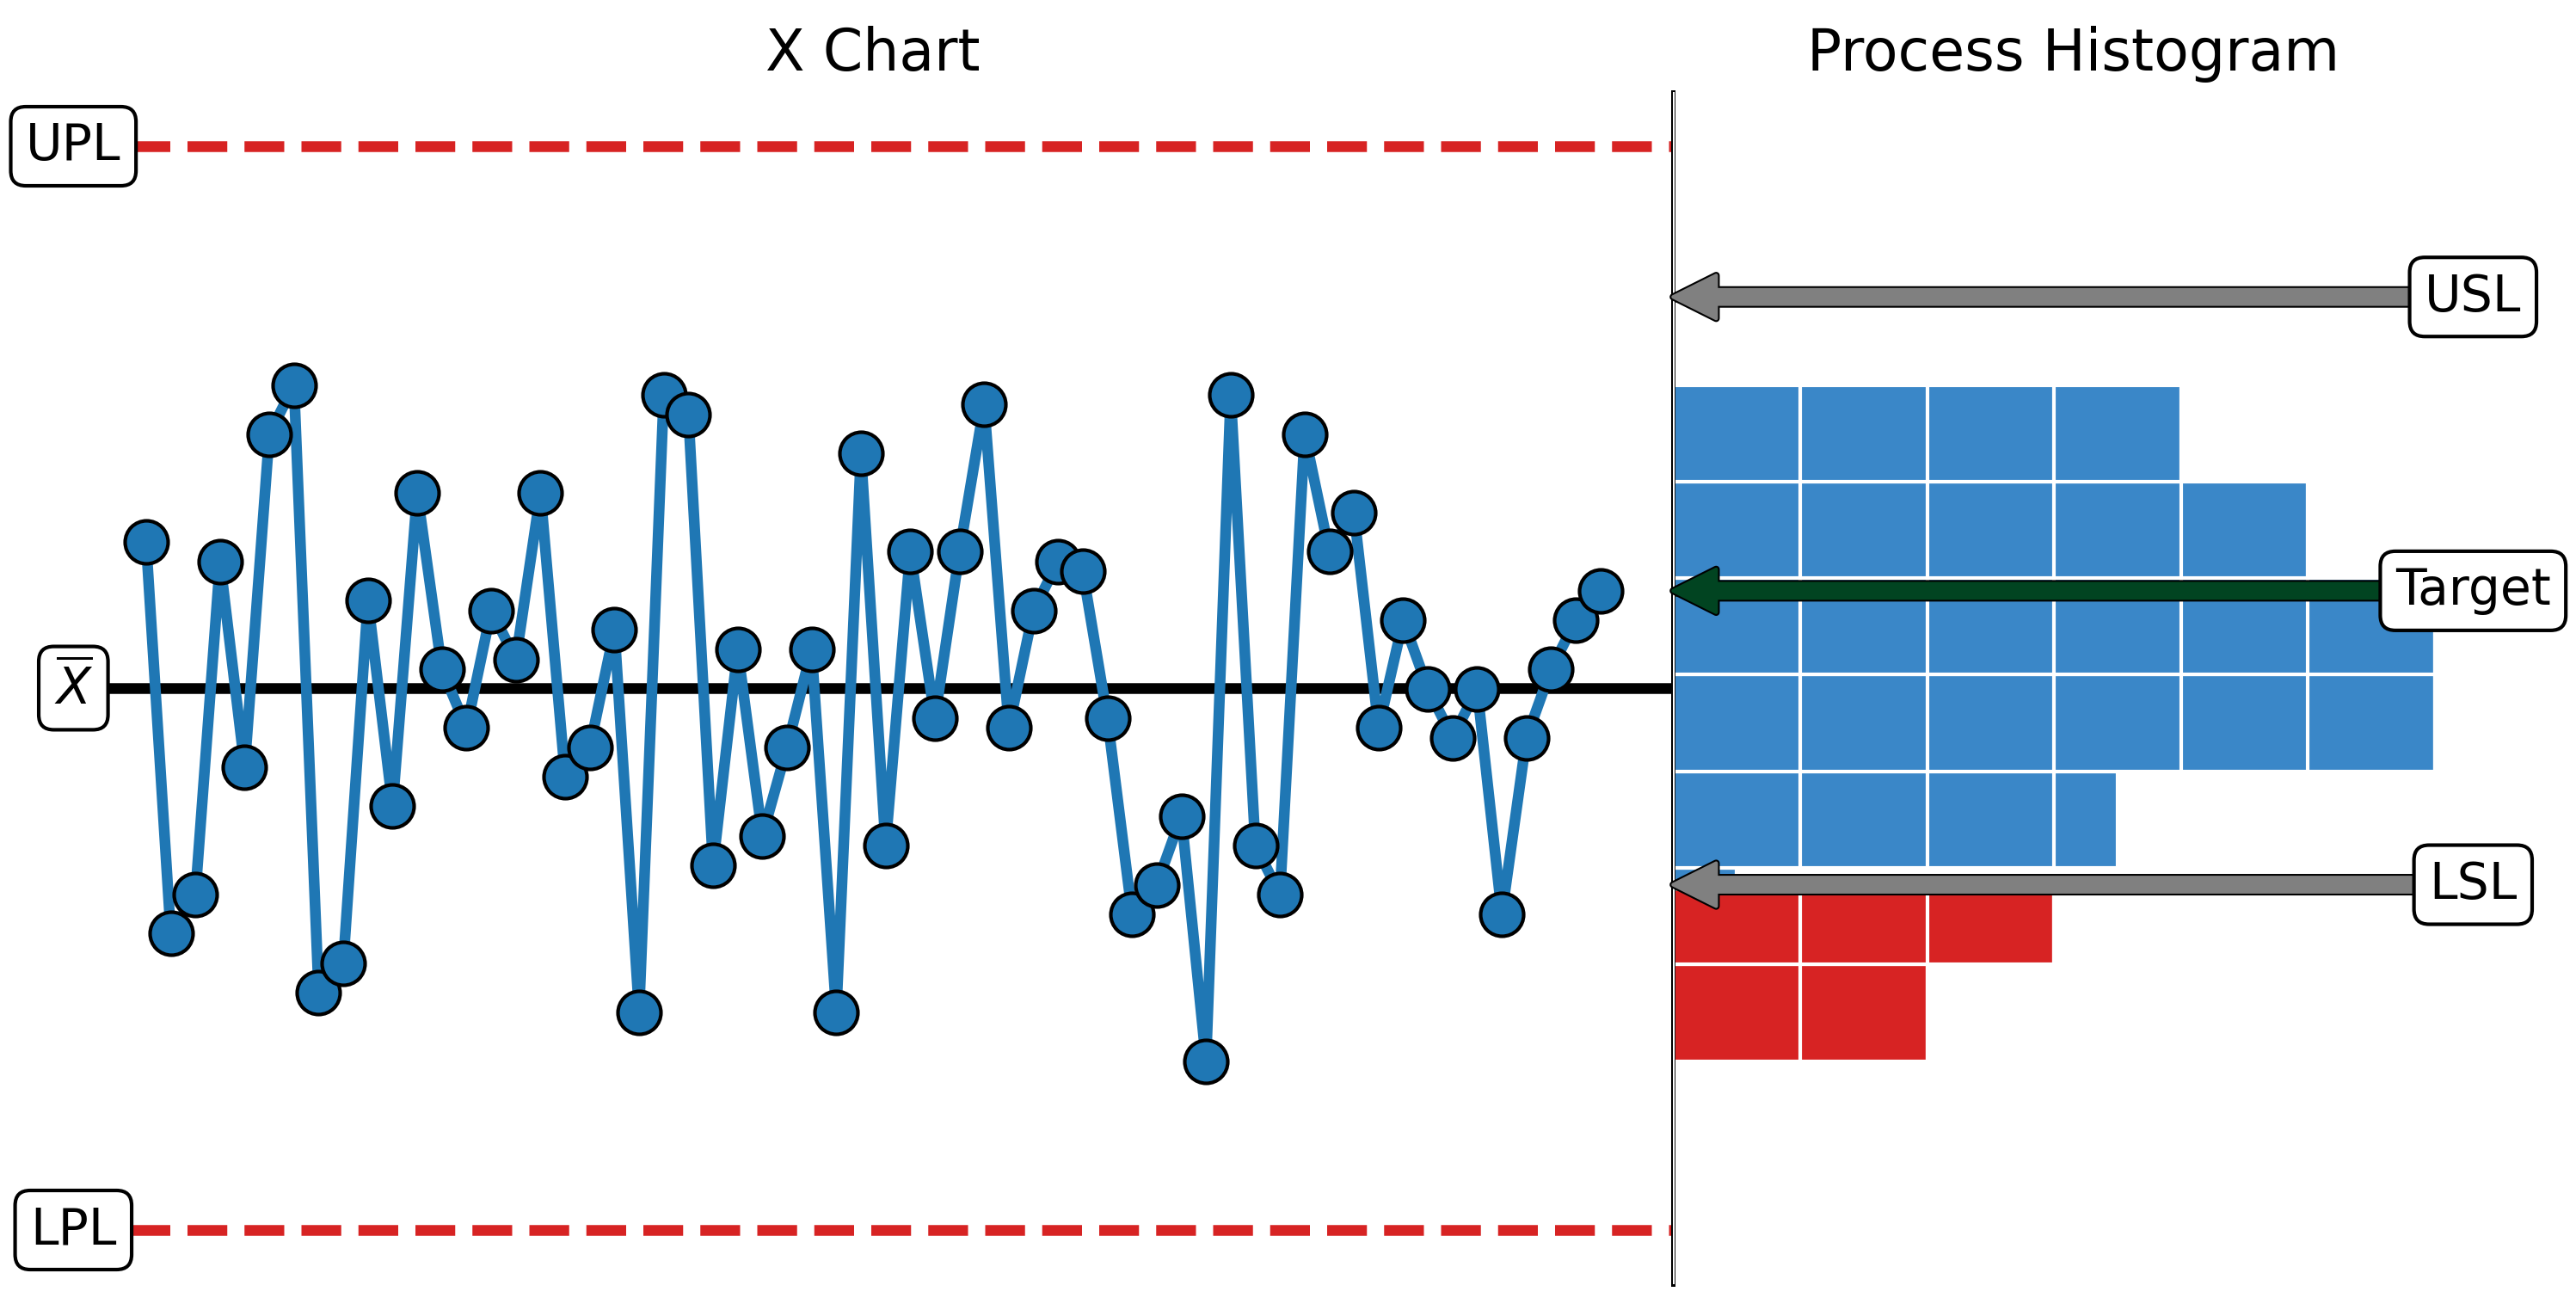

In [158]:
machine_screw_3_df['Sample'] = np.arange(1, len(machine_screw_3_df) + 1)
machine_screw_3_df = machine_screw_3_df.drop(columns=['MACHINE', 'DAY', 'SAMPLE', 'TIME (1 = AM, 2 = PM)'])


data = machine_screw_3_df['DIAMETER (in)']
labels = machine_screw_3_df['Sample']

USL = 0.128
LSL = 0.122
Target = 0.125

combo_chart(data, labels, USL, LSL, Target)